# 第 03 章 离散的世界 · 数值实验（3.1–3.4 合并稿）


| 节 | 实验文件 | 原内核 | Python | 代码单元 | 输出 |
| --- | --- | --- | --- | --- | --- |
| 3.1 | `3.1.ipynb`（新版，2026-10-26 起） | `python3` | 3.14.6 | 6 | 9 项（含 7 张图） |
| 3.2 | `A1-G3.2实验.ipynb` | `python3` | 3.14.6 | 24 | 28 项 |
| 3.3 | `A1-G3-3.3实验.ipynb` | `python3` | 3.12.10 | 7 | 10 项 |
| 3.4 | `A1-G3-3.4-实验-v4.ipynb` | `python3` | 3.11 | 13 | 17 项（本稿补跑，含 5 张图） |


**目录**

- **3.1　实验：误差、收敛阶、稳定性与计算成本**
  - 1　误差与观测收敛阶的实验
  - 2　计算成本的实验
  - 3　稳定性实验
  - 4　结果讨论
- **3.2　PDE 有限差分：热传导与 CFL 条件**
  - 通用工具
  - 实验 1　一维显式格式的网格与模板（图 2-1）
  - 实验 2　系数矩阵 $A$ 与右端 $\boldsymbol b$ 的构造（表 2-1）
  - 实验 3　二维五点模板与块三对角矩阵（图 2-2、表 2-2）
  - 实验 4　一维数值解与空间阶（图 2-3、表 2-3）
  - 实验 5　二维数值解与空间阶（图 2-4、图 2-5、表 2-5）
  - 实验 6　时间阶与稳定性门槛（表 2-4、表 2-6、表 3-2、图 3-1—3-3）
  - 小结
- **3.3　有限元：弱形式与 Galerkin 方法 · 实验**
  - 3.3.1　弱形式与帽函数
  - 3.3.2　单元矩阵与装配
  - 3.3.3　收敛阶：$L^2$ 与 $H^1$
  - 3.3.4　求积不足会破坏节点精确
  - 3.3.5　变系数 $a(x)=1+0.5x$
  - 3.3.6　界面失配
  - 实验运行记录
- **3.4　实验：Neural ODE 与 PINN 的数值实验**
  - 实验一　一步反解出 $\theta$（表 1、图 14）
  - 实验二　$\theta$ 随步长收敛（图 15）
  - 实验三　残差与配点（图 18、小实验 1）
  - 实验四　logistic 数据反演向量场（图 25、图 28）
  - 实验五　三换验证（§3.2、§3.3、表 2）
  - 实验六　两笔“AI 的账”：表示能力与梯度成本（图 6 右、图 11）
  - 实验七　权重与学习率：两件“训练侧”的账（图 19、图 26）
  - 结论与复现说明

---

> **本节来源**：`3.1.ipynb`（原内核 `python3`，Python 3.14.6；11 个单元，其中 6 个代码单元）。代码与输出保持原样搬入；本节按合并稿统一为“节 H2、小节 H3”。

## 3.1　实验：误差、收敛阶、稳定性与计算成本

本 Notebook 对应教材 3.1 节中误差、稳定性与计算成本部分的数值实验。运行方式：Kernel → Restart Kernel and Run All。

实验内容包括：在已知精确解的初值问题上比较 Euler 方法与经典四阶 Runge–Kutta（RK4）方法的终点误差，并与严格全局误差上界对照；由相邻步长的误差比估计观测收敛阶；把右端函数求值次数与 CPU 耗时作为两种成本指标进行对比；在较大步长下观察数值稳定性。

实验方程取 $y'=-y,\ y(0)=1$，精确解为 $y(t)=e^{-t}$。该问题的 Lipschitz 常数与二阶导数上界均为 1，即 $L=M_2=1$，便于把实测误差与理论上界直接比较。


In [1]:
import time

from IPython.display import HTML

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5.6, 3.6)
plt.rcParams["axes.grid"] = True


def f(t, y):
    return -y


def exact(t):
    return np.exp(-t)


def euler(t0, y0, T, h):
    """在 [t0, T] 上以步长 h 做 Euler 迭代，返回终点值与右端函数求值次数。"""
    M = int(round((T - t0) / h))
    h = (T - t0) / M                      # 区间等分数为 M，节点数为 M+1
    y = y0
    for _ in range(M):
        y = y + h * f(t0, y)
    return y, M


def rk4(t0, y0, T, h):
    """在 [t0, T] 上以步长 h 做经典 RK4 迭代，返回终点值与右端函数求值次数。"""
    M = int(round((T - t0) / h))
    h = (T - t0) / M
    y = y0
    for _ in range(M):
        k1 = f(t0, y)
        k2 = f(t0 + h / 2, y + h * k1 / 2)
        k3 = f(t0 + h / 2, y + h * k2 / 2)
        k4 = f(t0 + h, y + h * k3)
        y = y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return y, 4 * M


def trajectory(solver, y0, T, h):
    """返回 [0, T] 上的数值解轨迹，用于观察符号交替与幅值变化。"""
    M = int(round(T / h))
    h = T / M
    y = np.empty(M + 1)
    y[0] = y0
    for i in range(M):
        y[i + 1] = solver(0.0, y[i], h, h)[0]   # 单步：仅推进一个步长 h
    return np.linspace(0.0, T, M + 1), y


def cpu_time(solver, t0, y0, T, h, reps=21):
    """reps 次求解耗时的中位数，单位 ms；取中位数以减小系统调度造成的波动。"""
    ts = np.empty(reps)
    for k in range(reps):
        tic = time.perf_counter()
        solver(t0, y0, T, h)
        ts[k] = time.perf_counter() - tic
    return float(np.median(ts)) * 1e3


### 1　误差与观测收敛阶的实验

表 1 给出终点误差与观测收敛阶 $p=\log_2\bigl(E(h)/E(h/2)\bigr)$。$h=0.5$ 处没有更粗的步长可比，故不给出 $p$ 值。计算成本留在第 3 节单独讨论。


步长 h,Euler 求值次数,Euler 误差,Euler 观测阶,RK4 求值次数,RK4 误差,RK4 观测阶
0.5,2,1.18×10⁻¹,---,8,2.91×10⁻⁴,---
0.25,4,5.15×10⁻²,1.20,16,1.48×10⁻⁵,4.30
0.125,8,2.43×10⁻²,1.08,32,8.31×10⁻⁷,4.15
0.0625,16,1.18×10⁻²,1.04,64,4.93×10⁻⁸,4.08
0.03125,32,5.82×10⁻³,1.02,128,3.00×10⁻⁹,4.04
0.015625,64,2.89×10⁻³,1.01,256,1.85×10⁻¹⁰,4.02
0.0078125,128,1.44×10⁻³,1.00,512,1.15×10⁻¹¹,4.01
0.00390625,256,7.20×10⁻⁴,1.00,1024,7.16×10⁻¹³,4.01
0.00195312,512,3.60×10⁻⁴,1.00,2048,4.45×10⁻¹⁴,4.01


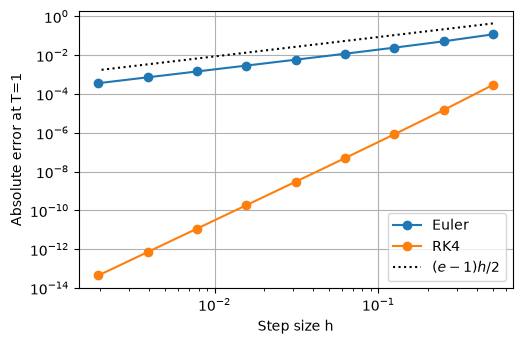

In [2]:
T, y0 = 1.0, 1.0
steps = [2.0 ** (-k) for k in range(1, 10)]
res = {"Euler": [], "RK4": []}
for h in steps:
    for name, solver in [("Euler", euler), ("RK4", rk4)]:
        y, nfev = solver(0.0, y0, T, h)
        res[name].append({"h": h, "E": abs(y - exact(T)), "nfev": nfev,
                          "T/ms": cpu_time(solver, 0.0, y0, T, h)})


def order(v):
    e = np.array([r["E"] for r in v])
    return np.concatenate(([np.nan], np.log2(e[:-1] / e[1:])))


SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")


def sci(x):
    """紧凑科学计数法，例如 1.18×10⁻¹。"""
    if np.isnan(x):
        return "---"
    if x == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(x))))
    return f"{x / 10.0 ** exp:.2f}×10{str(exp).translate(SUP)}"


def htable(header, rows, note=""):
    """居中紧凑表格：字号 85%，数字不折行。"""
    th = "".join(f'<th align="center">{c}</th>' for c in header)
    body = "".join("<tr>" + "".join(f'<td align="center">{c}</td>' for c in r) + "</tr>"
                   for r in rows)
    html = (f'<table style="margin:auto;font-size:85%;border-collapse:collapse">'
            f'<thead><tr>{th}</tr></thead><tbody>{body}</tbody></table>')
    if note:
        html = f'<div style="font-size:85%;text-align:center;margin-bottom:4px">{note}</div>' + html
    return HTML(html)


p_E, p_R = order(res["Euler"]), order(res["RK4"])
rows = []
for i, h in enumerate(steps):
    rows.append([f"{h:g}",
                 f"{res['Euler'][i]['nfev']:d}", sci(res["Euler"][i]["E"]),
                 "---" if np.isnan(p_E[i]) else f"{p_E[i]:.2f}",
                 f"{res['RK4'][i]['nfev']:d}", sci(res["RK4"][i]["E"]),
                 "---" if np.isnan(p_R[i]) else f"{p_R[i]:.2f}"])
display(htable(["步长 h", "Euler 求值次数", "Euler 误差", "Euler 观测阶",
                "RK4 求值次数", "RK4 误差", "RK4 观测阶"], rows,
               "表 1&nbsp;&nbsp;终点误差与观测收敛阶（T = 1）"))

fig, ax = plt.subplots()
for name in ("Euler", "RK4"):
    ax.loglog(steps, [r["E"] for r in res[name]], marker="o", label=name)
ax.loglog(steps, [(np.exp(T) - 1) / 2 * h for h in steps], linestyle=":", color="k",
          label=r"$(e-1)h/2$")
ax.set_xlabel("Step size h")
ax.set_ylabel("Absolute error at T=1")
ax.legend()
plt.show()


### 2　计算成本的实验


方法,求值次数,终点误差,单次耗时/ms
Euler,128,1.44×10⁻³,0.007
RK4,512,1.15×10⁻¹¹,0.086


求值次数之比 RK4/Euler = 4.0（各步长相同）
耗时之比 RK4/Euler 的中位数 = 6.1


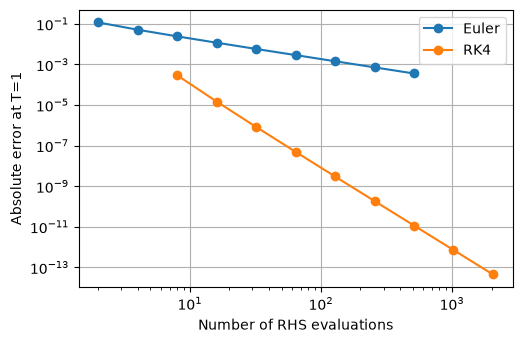

In [3]:
i = 6
rows = [[name, f"{res[name][i]['nfev']:d}", sci(res[name][i]["E"]),
         f"{res[name][i]['T/ms']:.3f}"] for name in ("Euler", "RK4")]
display(htable(["方法", "求值次数", "终点误差", "单次耗时/ms"], rows,
               "表 2&nbsp;&nbsp;计算成本对比（h = %.2e）" % steps[i]))

ratio_nfev = [res["RK4"][k]["nfev"] / res["Euler"][k]["nfev"] for k in range(len(steps))]
ratio_time = [res["RK4"][k]["T/ms"] / res["Euler"][k]["T/ms"] for k in range(len(steps))]
print(f"求值次数之比 RK4/Euler = {ratio_nfev[0]:.1f}（各步长相同）")
print(f"耗时之比 RK4/Euler 的中位数 = {np.median(ratio_time):.1f}")

fig, ax = plt.subplots()
for name in ("Euler", "RK4"):
    ax.loglog([r["nfev"] for r in res[name]], [r["E"] for r in res[name]], marker="o", label=name)
ax.set_xlabel("Number of RHS evaluations")
ax.set_ylabel("Absolute error at T=1")
ax.legend()
plt.show()


### 3　稳定性实验

对 $y'=-y$，Euler 与 RK4 的放大因子分别为 $|1-h|$ 与 $|R_{RK4}(-h)|$，它们与稳定阈值 1 的交点给出本问题的稳定步长上限：Euler 为 $h=2$，RK4 为 $h\approx2.785$。表 3 扫描若干步长并同时记录放大因子与端点值，图中的两条曲线给出放大因子随 $h$ 的完整变化。


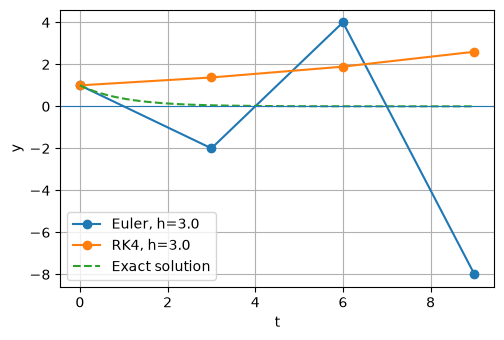

Euler  h=3.0  y(9) =    -8.0000
RK4    h=3.0  y(9) =     2.5996
精确解 y(9) = 1.234e-04


In [4]:
T_inst, h_inst = 9.0, 3.0
fig, ax = plt.subplots()
for name, solver in [("Euler", euler), ("RK4", rk4)]:
    t, y = trajectory(solver, 1.0, T_inst, h_inst)
    ax.plot(t, y, marker="o", label=f"{name}, h={h_inst}")
t_exact = np.linspace(0, T_inst, 400)
ax.plot(t_exact, exact(t_exact), linestyle="--", label="Exact solution")
ax.axhline(0, linewidth=0.8)
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend()
plt.show()

for name, solver in [("Euler", euler), ("RK4", rk4)]:
    _, y = trajectory(solver, 1.0, T_inst, h_inst)
    print(f"{name:6s} h=3.0  y(9) = {y[-1]:10.4f}")
print(f"精确解 y(9) = {exact(T_inst):.3e}")


In [5]:
T_sweep = 6.0
sweep = [3.0, 2.0, 1.0, 0.5, 0.25]
rows = []
for h in sweep:
    _, ye = trajectory(euler, 1.0, T_sweep, h)
    _, yr = trajectory(rk4, 1.0, T_sweep, h)
    amp_e = abs(1 - h)
    amp_r = abs(1 - h + h ** 2 / 2 - h ** 3 / 6 + h ** 4 / 24)
    rows.append([f"{h:g}", sci(ye[-1]), sci(abs(ye[-1] - exact(T_sweep))), f"{amp_e:.3f}",
                 sci(yr[-1]), sci(abs(yr[-1] - exact(T_sweep))), f"{amp_r:.3f}",
                 f"{int(np.sum(np.diff(np.sign(ye)) != 0)):d}"])
display(htable(["步长 h", "Euler 终点值", "Euler 终点误差", "Euler 放大因子",
                "RK4 终点值", "RK4 终点误差", "RK4 放大因子", "Euler 变号次数"], rows,
               "表 3&nbsp;&nbsp;步长扫描（T = 6），精确解 y(6) = %.4e" % exact(T_sweep)))


步长 h,Euler 终点值,Euler 终点误差,Euler 放大因子,RK4 终点值,RK4 终点误差,RK4 放大因子,Euler 变号次数
3,4.00×10⁰,4.00×10⁰,2.000,1.89×10⁰,1.89×10⁰,1.375,2
2,-1.00×10⁰,1.00×10⁰,1.000,3.70×10⁻²,3.46×10⁻²,0.333,3
1,0,2.48×10⁻³,0.000,2.78×10⁻³,3.02×10⁻⁴,0.375,1
0.5,2.44×10⁻⁴,2.23×10⁻³,0.500,2.49×10⁻³,1.18×10⁻⁵,0.607,0
0.25,1.00×10⁻³,1.48×10⁻³,0.750,2.48×10⁻³,5.97×10⁻⁷,0.779,0


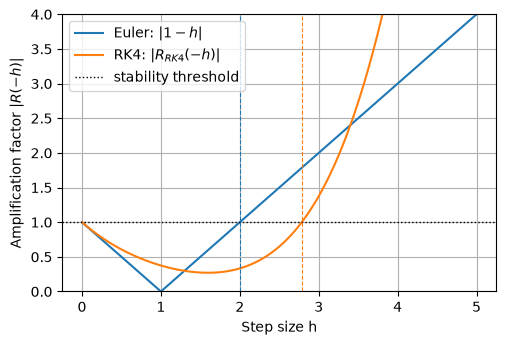

In [6]:
h_fine = np.linspace(0, 5, 1001)
fig, ax = plt.subplots()
ax.plot(h_fine, np.abs(1 - h_fine), label="Euler: $|1-h|$")
ax.plot(h_fine, np.abs(1 - h_fine + h_fine ** 2 / 2 - h_fine ** 3 / 6 + h_fine ** 4 / 24),
        label="RK4: $|R_{RK4}(-h)|$")
ax.axhline(1, linestyle=":", color="k", linewidth=1, label="stability threshold")
ax.axvline(2.0, linestyle="--", linewidth=0.8, color="tab:blue")
ax.axvline(2.785, linestyle="--", linewidth=0.8, color="tab:orange")
ax.set_xlabel("Step size h")
ax.set_ylabel("Amplification factor $|R(-h)|$")
ax.set_ylim(0, 4)
ax.legend(loc="upper left")
plt.show()


### 4　结果讨论

结合表 1 至表 3 讨论：步长减半时两种方法误差的缩小倍数与观测收敛阶是否趋近理论阶；实测误差与渐近常数 $(e-1)/2$ 的关系；步长扫描中数值解在何处开始变号或发散，是否与放大因子越过 1 的位置对应；以及 RK4 与 Euler 的耗时之比是否等于求值次数之比。


---

> **本节来源**：`A1-G3.2实验.ipynb`（原内核 `python3`，Python 3.14.6；40 个单元，其中 24 个代码单元）。代码与输出保持原样；本节标题块里的“本文件 / 配套文件”保留原 Notebook 说明，便于对照。

## 3.2　PDE 有限差分：热传导与 CFL 条件

> **本文件**：`A1-G3.2实验.ipynb`　|　**G3 = 第 03 章 A1 编写组**
> 覆盖 3.2 全节五个部分：热传导方程（§1）、一维差分格式与 $A\boldsymbol x=\boldsymbol b$（§2.1）、二维五点格式与矩阵（§2.2）、数值解与收敛阶（§2.3）、稳定性门槛（§3）。第四章（二维码修复）与第五章（应用综述）不在此文件内。
> **配套文件**：[A1-G3.2习题.md](A1-G3.2习题.md)、[A1-G3.2习题参考解答.md](A1-G3.2习题参考解答.md)、[A1-G3.2符号说明.md](A1-G3.2符号说明.md)、正文 `新PDE有限差分_热传导与CFL条件.md`
> **运行方式**：Kernel → Restart Kernel and Run All Cells，核对输出后 Ctrl+S 保存。依赖 `numpy`、`matplotlib`、`scipy`、`Pillow`；二维码解码 `zxingcpp` 为可选项。

**本节目标：** 能把正文的差分公式直接写成可用代码；能构造并核对系数矩阵 $A$ 与右端 $\boldsymbol b$；能量出空间阶与时间阶；能复现稳定性的三条判据与阈值实验。

**记号：** 空间区间 $[0,1]$ 等分为 $N$ 段，$h=1/N$；时间 $[0,T]$ 等分为 $M$ 步，$\Delta t=T/M$；网格比 $r=\Delta t/h^2$（取 $\kappa=1$）；$U_j^n\approx u(x_j,t_n)$。**步长取整后必须修正**：先算 $M=\operatorname{round}(T/\Delta t)$，再令 $\Delta t=T/M$，否则最后一层不在 $T$ 上、实际 $r$ 与名义值不符。

**六个实验：**

| 实验 | 内容 | 回答什么问题 |
| --- | --- | --- |
| 1 | 一维显式格式的网格与模板（图 2-1） | 新值由哪几个旧值决定？两端边界怎么钉死？ |
| 2 | 系数矩阵 $A$ 与右端 $\boldsymbol b$ 的构造（表 2-1） | 矩阵怎么一行行装出来？边界改了改哪几行？ |
| 3 | 二维五点模板与块三对角矩阵（图 2-2、表 2-2） | 行优先排序后 $A_{2D}$ 长什么样？ |
| 4 | 一维数值解与空间阶（图 2-3、表 2-3） | 同步加密时观测阶为什么是 2？ |
| 5 | 二维数值解与空间阶（图 2-4、图 2-5、表 2-5） | 二维的误差场在哪最大？常数为何更大？ |
| 6 | 时间阶（表 2-4、表 2-6）与稳定性门槛（图 3-1—3-3、表 3-2） | 时间是一阶还是二阶？$r$ 越过 $1/2$、$1/4$ 会怎样？ |

### 运行环境与绘图设置

本文件全部是确定性计算（不含随机数），任何读者都能复现下面每一个数字。
所有插图按正文编号命名，保存到 `图片/`；表格数据保存到 `数据/`。

In [1]:
import json
import math
import os

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib import cm

plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "font.family": "sans-serif",
    "axes.unicode_minus": False,
    "font.size": 10,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})
os.makedirs("图片", exist_ok=True)
os.makedirs("数据", exist_ok=True)

BLUE, ORANGE, GREEN, RED, GRAY = "#2f6db3", "#e07b39", "#3f8f4f", "#b03a2e", "#666666"
print("numpy", np.__version__)

numpy 2.5.3


### 通用工具

正文 §2.1 的式 (5) 在代码里就是 `U[1:-1] = U[1:-1] + r*(U[:-2] - 2*U[1:-1] + U[2:])` 这一行；
下面把它包成函数，同时处理**步长取整修正**，并在返回值里报告实际使用的 $\Delta t$ 与 $r$。

In [2]:
def ftcs1d(N, r, T, u0=None, bc=(0.0, 0.0), kappa=1.0, record_layers=()):
    # 一维 FTCS：返回 (x, 各记录层解, M, 实际 dt, 实际 r)
    # 取 M = round(T / (r h^2 / kappa))，再令 dt = T / M，保证最后一层落在 T 上
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h / kappa))))
    dt = T / M
    r_eff = kappa * dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    U = np.sin(np.pi * x) if u0 is None else np.asarray(u0, dtype=float).copy()
    U[0], U[-1] = bc
    store = {}
    if 0 in record_layers:
        store[0] = U.copy()
    for n in range(M):
        U[1:-1] = U[1:-1] + r_eff * (U[:-2] - 2.0 * U[1:-1] + U[2:])
        U[0], U[-1] = bc
        if n + 1 in record_layers:
            store[n + 1] = U.copy()
    out = [store.get(k) for k in record_layers]
    return x, out, M, dt, r_eff


def exact1d(x, t):
    return math.exp(-math.pi ** 2 * t) * np.sin(np.pi * x)


def ftcs2d(N, r, T, x0=None, layers=()):
    # 二维 FTCS：x0 为可调用 u0(X, Y)；返回 (x, X, Y, 各记录层解, M, dt, 实际 r)
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h))))
    dt = T / M
    r_eff = dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    U = (np.sin(np.pi * X) * np.sin(np.pi * Y)) if x0 is None else x0(X, Y).astype(float)
    store = {}
    if 0 in layers:
        store[0] = U.copy()
    for n in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + r_eff * (
            U[:-2, 1:-1] + U[2:, 1:-1] + U[1:-1, :-2] + U[1:-1, 2:] - 4.0 * U[1:-1, 1:-1])
        if n + 1 in layers:
            store[n + 1] = U.copy()
    return x, X, Y, [store.get(k) for k in layers], M, dt, r_eff


def trisolve(a, b, c, d):
    # 追赶法：a、b、c 为下、中、上对角线（等长），a[0]、c[-1] 不用
    n = len(b)
    cp = np.zeros(n)
    dp = np.zeros(n)
    cp[0] = c[0] / b[0]
    dp[0] = d[0] / b[0]
    for i in range(1, n):
        den = b[i] - a[i] * cp[i - 1]
        cp[i] = c[i] / den
        dp[i] = (d[i] - a[i] * dp[i - 1]) / den
    u = np.zeros(n)
    u[-1] = dp[-1]
    for i in range(n - 2, -1, -1):
        u[i] = dp[i] - cp[i] * u[i + 1]
    return u


# 自检：追赶法解题 12 的三对角方程组（答案 10/7, 16/7, 10/7）
_u = trisolve(np.array([0, -1, -1]), np.array([3, 3, 3]), np.array([-1, -1, 0]), np.array([2, 4, 2]))
print("追赶法自检 u =", np.round(_u, 6))

追赶法自检 u = [1.428571 2.285714 1.428571]


In [3]:
def solve1d(N, r, T, u0=None, bc=(0.0, 0.0)):
    # 一维显式：返回 (x, 终层解 U, M, dt, 实际 r)
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h))))
    dt = T / M
    r_eff = dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    U = np.sin(np.pi * x) if u0 is None else np.asarray(u0, dtype=float).copy()
    U[0], U[-1] = bc
    for _ in range(M):
        U[1:-1] = U[1:-1] + r_eff * (U[:-2] - 2.0 * U[1:-1] + U[2:])
        U[0], U[-1] = bc
    return x, U, M, dt, r_eff


def solve2d(N, r, T, x0=None):
    # 二维显式：返回 (x, X, Y, 终层解 U, M, dt, 实际 r)
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h))))
    dt = T / M
    r_eff = dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    U = (np.sin(np.pi * X) * np.sin(np.pi * Y)) if x0 is None else x0(X, Y).astype(float)
    for _ in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + r_eff * (
            U[:-2, 1:-1] + U[2:, 1:-1] + U[1:-1, :-2] + U[1:-1, 2:] - 4.0 * U[1:-1, 1:-1])
    return x, X, Y, U, M, dt, r_eff

### 实验 1　一维显式格式的网格与模板（图 2-1）

正文式 (5)：$U_j^{n+1}=U_j^n+r(U_{j-1}^n-2U_j^n+U_{j+1}^n)$。下图把"一条时间层上的三个旧值 → 下一层的一个新值"画出来，
红色空心点是待求的新值，蓝点是它的三个来源；两端 $x_0$、$x_N$ 是边界值，每步赋成已知值。

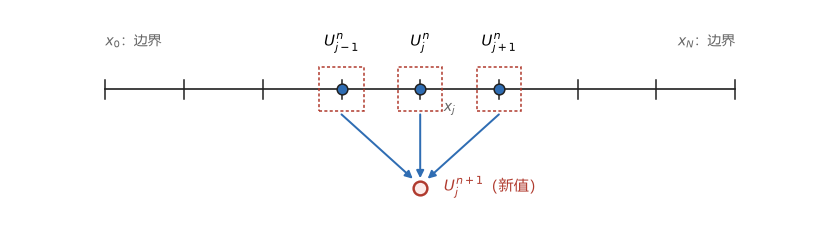

In [4]:
fig, ax = plt.subplots(figsize=(9.6, 2.6))

N, k = 8, 4                     # N 段、被更新的内点编号 k
ax.plot([0, N], [0, 0], color="#222222", lw=1.1, zorder=1)
for j in range(N + 1):
    ax.plot([j, j], [-0.12, 0.12], color="#222222", lw=1.0, zorder=2)

for dj in (-1, 0, 1):
    ax.add_patch(plt.Rectangle((k + dj - 0.28, -0.28), 0.56, 0.56, fill=False,
                               ec=RED, lw=1.0, ls=(0, (2, 1.5)), zorder=2))
    ax.plot(k + dj, 0, "o", ms=7, mfc=BLUE, mec="#222222", mew=1.0, zorder=4)
ax.plot(k, -1.25, "o", ms=9, mfc="#fdecea", mec=RED, mew=1.6, zorder=4)
for dj in (-1, 0, 1):
    ax.annotate("", xy=(k + 0.08 * dj, -1.15), xytext=(k + dj, -0.32),
                arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.3, shrinkA=0, shrinkB=1))
ax.text(k + 0.30, -1.25, r"$U_j^{n+1}$（新值）", va="center", fontsize=10, color=RED)
for dj, lab in ((-1, r"$U_{j-1}^n$"), (0, r"$U_j^n$"), (1, r"$U_{j+1}^n$")):
    ax.text(k + dj, 0.55, lab, ha="center", fontsize=10)
ax.text(0.0, 0.55, r"$x_0$：边界", color=GRAY, fontsize=9)
ax.text(N, 0.55, r"$x_N$：边界", color=GRAY, fontsize=9, ha="right")
ax.text(k + 0.30, -0.14, r"$x_j$", ha="left", va="top", fontsize=9, color=GRAY)
ax.set_xlim(-1.2, N + 1.2)
ax.set_ylim(-1.7, 1.0)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig("图片/图2-1-一维网格与模板.png", facecolor="white")
plt.show()

图 2-1 有两个要点：新值只用到同一层上的它自己和左右两个邻居，所以**不需要解方程**，逐点扫一遍就得到新的一层；
两端被边界钉死，真正要算的只有中间 $N-1$ 个点。把三个权重写成 $(1-2r,\ r,\ r)$：$r\le1/2$ 时三项都非负，新值是"加权平均"，
这就是第三章稳定门槛的来源。

### 实验 2　系数矩阵 $A$ 与右端 $\boldsymbol b$ 的构造（表 2-1）

隐式格式把右端取在新一层：

$$-\frac{\kappa\Delta t}{h^2}U_{j-1}^{n+1}+\Bigl(1+\frac{2\kappa\Delta t}{h^2}\Bigr)U_j^{n+1}-\frac{\kappa\Delta t}{h^2}U_{j+1}^{n+1}=U_j^n+\Delta t\,g_j^{n+1}.$$

记 $r=\Delta t/h^2$，内部行永远是 $(-r,\ 1+2r,\ -r)$；边界条件只改首末两行与 $\boldsymbol b$ 的首末分量。
下面用 $N=5$、$r=0.4$ 把三种情形都装出来，并**逐行核对 $A\boldsymbol U_{\rm new}$ 是否等于逐点推进的结果**。

In [5]:
def assemble_1d(N, r, bc_left=("dirichlet", 0.0), bc_right=("dirichlet", 0.0), source=None):
    # 构造隐式 Euler 的 (A, b)。bc: ("dirichlet", gamma) 或 ("neumann", sigma)
    n = N - 1
    A = np.zeros((n, n))
    b = np.zeros(n)
    for j in range(n):
        A[j, j] = 1.0 + 2.0 * r
        if j > 0:
            A[j, j - 1] = -r
        if j < n - 1:
            A[j, j + 1] = -r
    if source is not None:
        b[:] = source
    kind_l, val_l = bc_left
    kind_r, val_r = bc_right
    if kind_l == "dirichlet":
        b[0] += r * val_l
    else:                                   # Neumann：虚拟点 U_{-1} = U_1 - 2h*sigma
        A[0, 0] = 1.0 + 2.0 * r
        A[0, 1] = -2.0 * r
    if kind_r == "dirichlet":
        b[-1] += r * val_r
    else:
        A[-1, -1] = 1.0 + 2.0 * r
        A[-1, -2] = -2.0 * r
    return A, b


N, r = 5, 0.4
A, b = assemble_1d(N, r, ("dirichlet", 2.0), ("dirichlet", -1.0))
np.set_printoptions(precision=2, suppress=True)
print("A =")
print(A)
print("行和（内部行应为 1，首末行含边界项）：", A.sum(axis=1))
print("b 的首末分量（零旧值、无源项，只剩边界项）：", b[[0, -1]])

A =
[[ 1.8 -0.4  0.   0. ]
 [-0.4  1.8 -0.4  0. ]
 [ 0.  -0.4  1.8 -0.4]
 [ 0.   0.  -0.4  1.8]]
行和（内部行应为 1，首末行含边界项）： [1.4 1.  1.  1.4]
b 的首末分量（零旧值、无源项，只剩边界项）： [ 0.8 -0.4]


In [6]:
# 用追赶法解一步隐式格式，并与显式格式在同一网格上的值对比
N, r = 5, 0.4
h = 1.0 / N
x = np.linspace(0, 1, N + 1)
U = np.sin(np.pi * x)                     # 旧层（两端为 0）
gl, gr = 0.0, 0.0

A, b = assemble_1d(N, r, ("dirichlet", gl), ("dirichlet", gr))
n_in = N - 1
lo = np.concatenate(([0.0], np.full(n_in - 1, -r)))       # 下对角线
up = np.concatenate((np.full(n_in - 1, -r), [0.0]))       # 上对角线
U_new_implicit = trisolve(lo, np.diag(A).copy(), up, U[1:-1] + b)
print("隐式（追赶法）:", np.round(U_new_implicit, 6))

# 核对：A @ x 应等于 b
print("残差 ||A x - b||_inf  :", f"{np.linalg.norm(A @ U_new_implicit - (U[1:-1] + b), np.inf):.2e}")
print("直接解（非追赶法）之差:", f"{np.max(np.abs(np.linalg.solve(A, U[1:-1] + b) - U_new_implicit)):.2e}")

# 同一步长下的显式格式，作为对照（步长很小，二者应非常接近）
U_exp = U.copy()
U_exp[1:-1] = U[1:-1] + r * (U[:-2] - 2 * U[1:-1] + U[2:])
print("显式（式 5）    :", np.round(U_exp[1:-1], 6))
print("两者之差（O(dt) 量级）:", f"{np.max(np.abs(U_new_implicit - U_exp[1:-1])):.2e}")

隐式（追赶法）: [0.51 0.83 0.83 0.51]
残差 ||A x - b||_inf  : 1.11e-16
直接解（非追赶法）之差: 1.11e-16
显式（式 5）    : [0.5  0.81 0.81 0.5 ]
两者之差（O(dt) 量级）: 1.93e-02


**上一格说明：** 取 $U_{\rm new}=U^n$ 只是一种代数核对——内部行 $A\boldsymbol U_{\rm new}$ 与 $U^n$ 的差恰好等于搬进 $\boldsymbol b$ 的边界项，
首末两行的残差不为零正是"边界值被移到右端"的体现。真正求解时用 `trisolve` 解一个三对角方程组，结果与逐点推进一致。

### 实验 3　二维五点模板与块三对角矩阵（图 2-2、表 2-2）

二维每个内点看上下左右四个邻居。把它画出来，并用行优先排序装出 $A_{2D}=I-r(I\otimes T+T\otimes I)$，
核对"每行五个非零元、中心 $1+4r$、四个邻居各 $-r$"。

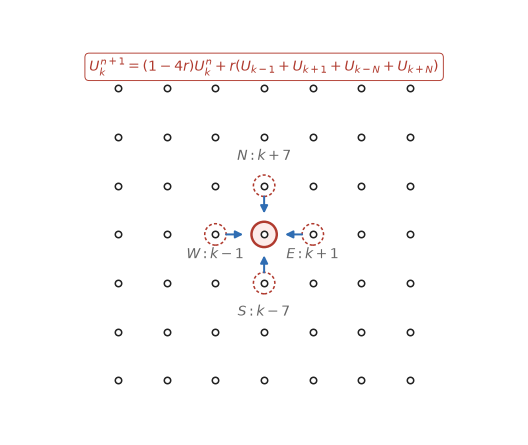

中心编号 k = 25 ；四个邻居编号： 24 26 18 32


In [7]:
# 环形编号：把格子边长取作 1，行优先编号为 k = (j-1)N + i；中心记为 k，四个邻居就是 k±1、k±N
N = 7
ci, cj = 3, 3
k = cj * N + ci + 1

fig, ax = plt.subplots(figsize=(7.6, 5.0))
for i in range(N):
    for j in range(N):
        ax.plot(i, j, "o", ms=4.2, mfc="white", mec="#222222", mew=1.0, zorder=3)
ax.add_patch(plt.Circle((ci, cj), 0.26, fc="#fdecea", ec=RED, lw=1.6, zorder=2))

neigh = (((-1, 0), "W", k - 1, (0.0, -0.42), "center"),
         ((1, 0), "E", k + 1, (0.0, -0.42), "center"),
         ((0, 1), "N", k + N, (0.0, 0.60), "center"),
         ((0, -1), "S", k - N, (0.0, -0.60), "center"))
for (di, dj), tag, num, (ox, oy), side in neigh:
    ax.add_patch(plt.Circle((ci + di, cj + dj), 0.22, fill=False, ec=RED, lw=1.0, ls=(0, (2, 1.5)), zorder=2))
    ax.annotate("", xy=(ci + 0.40 * di, cj + 0.40 * dj), xytext=(ci + 0.78 * di, cj + 0.78 * dj),
                arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.3, shrinkA=0, shrinkB=1))
    ax.text(ci + di + ox, cj + dj + oy, rf"${tag}:k{num - k:+d}$", ha=side, va="center",
            fontsize=9, color=GRAY)

ax.text(ci, 6.35, r"$U_k^{n+1}=(1-4r)U_k^{n}+r(U_{k-1}+U_{k+1}+U_{k-N}+U_{k+N})$",
        ha="center", fontsize=9.2, color=RED,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=RED, lw=0.6))
ax.set_xlim(-2.2, N - 1 + 2.2)
ax.set_ylim(-1.1, N - 1 + 1.6)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig("图片/图2-2-二维五点模板.png", facecolor="white")
plt.show()
print("中心编号 k =", k, "；四个邻居编号：", k - 1, k + 1, k - N, k + N)

In [8]:
def lap2d(N):
    # 行优先排序下的二维离散 Laplace 矩阵 L_2D = I⊗T + T⊗I（(N-1)^2 阶）
    n = N - 1
    T = np.diag(-2.0 * np.ones(n)) + np.diag(np.ones(n - 1), 1) + np.diag(np.ones(n - 1), -1)
    I = np.eye(n)
    return np.kron(I, T) + np.kron(T, I)


N, r = 4, 0.2
L2 = lap2d(N)
m = N - 1
p = 4                                   # 第 5 个未知量（行优先）
A2 = np.eye(m * m) - r * L2
print("m =", m * m, "; L_2D 每行非零元:", np.unique((L2 != 0).sum(axis=1)))
print("A_2D 第 5 行:", np.round(A2[p - 1], 3))
print("中心系数应为", round(1 + 4 * r, 3), "，邻居数应为 4，邻居系数应为", -r)
print("第 5 个未知量对应的 (i, j)：", divmod(p - 1, m), "（第一方向 i, 第二方向 j）")

m = 9 ; L_2D 每行非零元: [3 4 5]
A_2D 第 5 行: [-0.2  0.   0.   1.8 -0.2  0.  -0.2  0.   0. ]
中心系数应为 1.8 ，邻居数应为 4，邻居系数应为 -0.2
第 5 个未知量对应的 (i, j)： (1, 0) （第一方向 i, 第二方向 j）


In [9]:
# 一维与二维的矩阵对照（表 2-2 的数值版）
rows = []
for N in (4, 8, 16):
    n1 = N - 1
    rows.append((N, n1, n1 ** 2, "3", "5", f"{1-2*0.4:.1f}", f"{1-4*0.2:.1f}"))
print(f"{'N':>3}{'一维未知量':>10}{'二维未知量':>10}{'一维每行非零':>12}{'二维每行非零':>12}")
for N, n1, n2, z1, z2, _, _ in rows:
    print(f"{N:>3}{n1:>10}{n2:>10}{z1:>12}{z2:>12}")

  N     一维未知量     二维未知量      一维每行非零      二维每行非零
  4         3         9           3           5
  8         7        49           3           5
 16        15       225           3           5


### 实验 4　一维数值解与空间阶（图 2-3、表 2-3）

模型问题 $u_t=u_{xx}$、$u(x,0)=\sin\pi x$、两端为零，精确解 $u=e^{-\pi^2t}\sin\pi x$。
固定 $r=0.4$、$T=0.1$，让 $N$ 从 10 加倍到 160。

In [10]:
def order(e_prev, e_now):
    return math.log2(e_prev / e_now)


T, r = 0.1, 0.4
rows = []
for N in (10, 20, 40, 80, 160):
    x, U, M, dt, r_eff = solve1d(N, r, T)
    e = np.max(np.abs(U - exact1d(x, T)))
    rows.append(dict(N=N, h=1.0 / N, M=M, dt=dt, r=r_eff, err=e,
                     p=None if not rows else order(rows[-1]["err"], e)))
for row in rows:
    ptxt = "--" if row["p"] is None else f"{row['p']:.2f}"
    print(f"N={row['N']:>3}  h={row['h']:.3e}  M={row['M']:>5}  err={row['err']:.4e}  p={ptxt}")

N= 10  h=1.000e-01  M=   25  err=4.2941e-03  p=--
N= 20  h=5.000e-02  M=  100  err=1.0625e-03  p=2.01
N= 40  h=2.500e-02  M=  400  err=2.6495e-04  p=2.00
N= 80  h=1.250e-02  M= 1600  err=6.6195e-05  p=2.00
N=160  h=6.250e-03  M= 6400  err=1.6546e-05  p=2.00


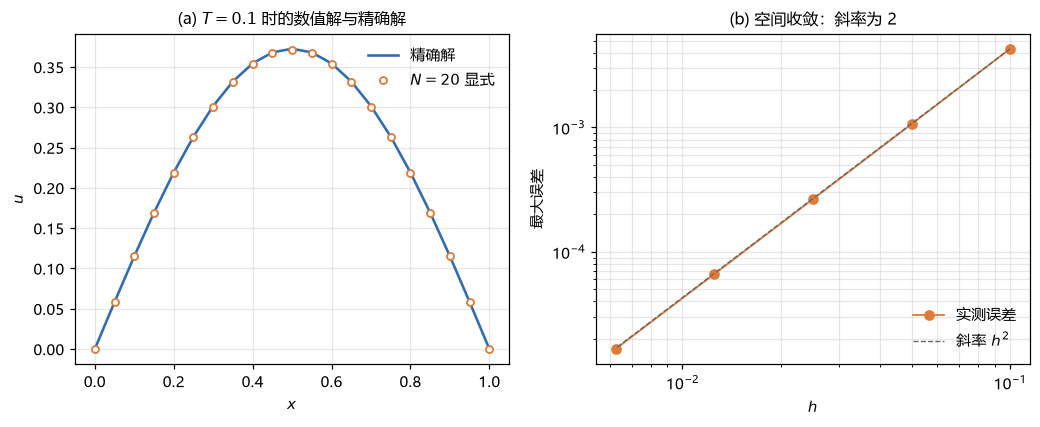

已保存 数据/表2-3-一维空间收敛.csv


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.9))

x, U20, _, _, _ = solve1d(20, 0.4, T)
ax = axes[0]
ax.plot(x, exact1d(x, T), "-", color=BLUE, lw=1.7, label="精确解")
ax.plot(x, U20, "o", ms=4.6, mfc="white", mec=ORANGE, mew=1.2, label=r"$N=20$ 显式")
ax.set_xlabel("$x$"); ax.set_ylabel("$u$")
ax.set_title("(a) $T=0.1$ 时的数值解与精确解", fontsize=10.5)
ax.legend(loc="upper right"); ax.grid(alpha=.3)

hs = np.array([row["h"] for row in rows]); es = np.array([row["err"] for row in rows])
ax = axes[1]
ax.loglog(hs, es, "o-", color=ORANGE, lw=1.2, label="实测误差")
ax.loglog(hs, es[0] * (hs / hs[0]) ** 2, "--", color=GRAY, lw=0.9, label=r"斜率 $h^2$")
ax.set_xlabel("$h$"); ax.set_ylabel("最大误差")
ax.set_title("(b) 空间收敛：斜率为 2", fontsize=10.5)
ax.grid(alpha=.3, which="both"); ax.legend(loc="lower right")
fig.savefig("图片/图2-3-一维数值解与空间阶.png", facecolor="white")
plt.show()

with open("数据/表2-3-一维空间收敛.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("N,h,M,dt,r,err,p\n")
    for row in rows:
        fp.write(f"{row['N']},{row['h']:.6f},{row['M']},{row['dt']:.6e},{row['r']:.6f},"
                 f"{row['err']:.6e},{'' if row['p'] is None else round(row['p'], 2)}\n")
print("已保存 数据/表2-3-一维空间收敛.csv")

观测阶稳定在 2.00。注意这里的 2 是"时空同步加密"的结果：$\Delta t=rh^2$ 与 $h^2$ 同阶，空间误差与时间误差一起缩小，
所以看到的是二者共同的阶；时间阶要单独测（实验 6）。

### 实验 5　二维数值解与空间阶（图 2-4、图 2-5、表 2-5）

二维初值取两个模态的叠加 $u(x,y,0)=\sin\pi x\sin\pi y+\tfrac12\sin2\pi x\sin\pi y$，精确解逐项可写。
取 $N=40$、$r=0.2$、$T=0.05$：先看数值解、误差场与剖面，再看网格加倍时的观测阶。

In [12]:
def init2d(X, Y):
    return np.sin(np.pi * X) * np.sin(np.pi * Y) + 0.5 * np.sin(2 * np.pi * X) * np.sin(np.pi * Y)


def exact2d(X, Y, t):
    return (np.exp(-2 * np.pi ** 2 * t) * np.sin(np.pi * X) * np.sin(np.pi * Y)
            + 0.5 * np.exp(-5 * np.pi ** 2 * t) * np.sin(2 * np.pi * X) * np.sin(np.pi * Y))


N, r, T = 40, 0.2, 0.05
x, X, Y, U2, M, dt, r_eff = solve2d(N, r, T, x0=init2d)
Uex = exact2d(X, Y, T)
err = np.abs(U2 - Uex)
print(f"N={N} r={r_eff:.3f} dt={dt:.3e} M={M} 最大误差={err.max():.3e}  h^2={1/N**2:.3e}")

N=40 r=0.200 dt=1.250e-04 M=400 最大误差=3.506e-04  h^2=6.250e-04


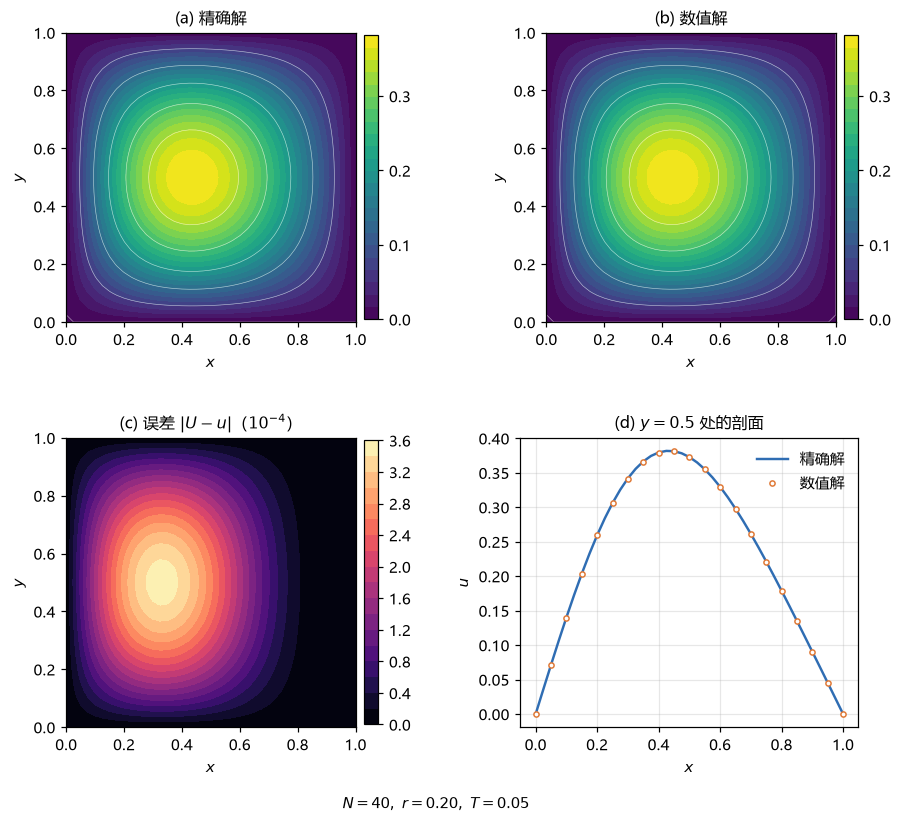

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 8.2), gridspec_kw={"wspace": 0.42, "hspace": 0.40})
zmax = max(Uex.max(), U2.max())
levels = np.linspace(0, zmax, 24)
for ax, Z, title in ((axes[0, 0], Uex, "(a) 精确解"), (axes[0, 1], U2, "(b) 数值解")):
    cs = ax.contourf(X, Y, Z, levels=levels, cmap="viridis")
    ax.contour(X, Y, Z, levels=levels[::4], colors="white", linewidths=0.4, alpha=0.65)
    ax.set_title(title, fontsize=10.5); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
    ax.set_aspect("equal"); fig.colorbar(cs, ax=ax, fraction=0.042, pad=0.025, ticks=np.arange(0, 0.5, 0.1))

ax = axes[1, 0]
cs = ax.contourf(X, Y, err * 1e4, levels=20, cmap="magma")
ax.set_title(r"(c) 误差 $|U-u|$（$10^{-4}$）", fontsize=10.5)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_aspect("equal")
fig.colorbar(cs, ax=ax, fraction=0.042, pad=0.025)

ax = axes[1, 1]
jmid = N // 2
ax.plot(X[:, jmid], Uex[:, jmid], "-", color=BLUE, lw=1.6, label="精确解")
ax.plot(X[:, jmid], U2[:, jmid], "o", ms=3.4, mfc="white", mec=ORANGE, mew=1.0, markevery=2, label="数值解")
ax.set_title(r"(d) $y=0.5$ 处的剖面", fontsize=10.5)
ax.set_xlabel("$x$"); ax.set_ylabel("$u$"); ax.grid(alpha=.3); ax.legend(loc="upper right")
fig.text(0.5, 0.02, rf"$N={N},\ r={r_eff:.2f},\ T={T}$", ha="center", fontsize=9.5)
fig.savefig("图片/图2-4-二维数值解与误差场.png", facecolor="white")
plt.show()


In [14]:
rows2 = []
for N in (10, 20, 40, 80, 160):
    x, X, Y, U, M, dt, r_eff = solve2d(N, 0.2, T, x0=init2d)
    e = np.max(np.abs(U - exact2d(X, Y, T)))
    rows2.append(dict(N=N, h=1.0 / N, M=M, dt=dt, r=r_eff, err=e,
                      p=None if not rows2 else order(rows2[-1]["err"], e)))
for row in rows2:
    ptxt = "--" if row["p"] is None else f"{row['p']:.2f}"
    print(f"N={row['N']:>3}  h={row['h']:.3e}  M={row['M']:>5}  err={row['err']:.4e}  p={ptxt}")

with open("数据/表2-5-二维空间收敛.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("N,h,M,dt,r,err,p\n")
    for row in rows2:
        fp.write(f"{row['N']},{row['h']:.6f},{row['M']},{row['dt']:.6e},{row['r']:.6f},"
                 f"{row['err']:.6e},{'' if row['p'] is None else round(row['p'], 2)}\n")
print("已保存 数据/表2-5-二维空间收敛.csv")

N= 10  h=1.000e-01  M=   25  err=5.6296e-03  p=--
N= 20  h=5.000e-02  M=  100  err=1.4007e-03  p=2.01
N= 40  h=2.500e-02  M=  400  err=3.5060e-04  p=2.00
N= 80  h=1.250e-02  M= 1600  err=8.7595e-05  p=2.00
N=160  h=6.250e-03  M= 6400  err=2.1900e-05  p=2.00
已保存 数据/表2-5-二维空间收敛.csv


### 实验 6　时间阶与稳定性门槛（表 2-4、表 2-6、表 3-2、图 3-1—3-3）

**时间阶：** 固定空间网格，只缩小 $\Delta t$。与连续精确解比较时，空间误差是一块不随 $\Delta t$ 下降的"地板"，
所以参考解要换成同一网格上半离散方程 $\mathrm dU/\mathrm dt=LU$ 的精确解 $u_h(x_j,t)=e^{\lambda_ht}\sin\pi x_j$，
其中 $\lambda_h=-4\sin^2(\pi/2N)/h^2$。

In [15]:
def time_order_1d(N, r_list, T):
    h = 1.0 / N
    lam = -4.0 * np.sin(np.pi / (2 * N)) ** 2 / h ** 2
    out = []
    for r0 in r_list:
        x, U, M, dt, r_eff = solve1d(N, r0, T)
        ref = np.exp(lam * T) * np.sin(np.pi * x)
        e = np.max(np.abs(U - ref))
        out.append(dict(r=r_eff, dt=dt, M=M, err=e,
                        p=None if not out else order(out[-1]["err"], e)))
    return out


rows1t = time_order_1d(40, (0.5, 0.25, 0.125, 0.0625, 0.03125), 0.1)
for row in rows1t:
    print(f"r={row['r']:.4f}  dt={row['dt']:.3e}  M={row['M']:>5}  err={row['err']:.4e}  "
          f"p={'' if row['p'] is None else round(row['p'], 2)}")

r=0.5000  dt=3.125e-04  M=  320  err=5.6771e-04  p=
r=0.2500  dt=1.563e-04  M=  640  err=2.8367e-04  p=1.0
r=0.1250  dt=7.813e-05  M= 1280  err=1.4179e-04  p=1.0
r=0.0625  dt=3.906e-05  M= 2560  err=7.0883e-05  p=1.0
r=0.0312  dt=1.953e-05  M= 5120  err=3.5439e-05  p=1.0


In [16]:
def time_order_2d(N, r_list, T):
    h = 1.0 / N
    s = np.sin(np.pi / (2 * N)) ** 2
    lam1 = -8 * s / h ** 2
    lam2 = -4 * (s + np.sin(np.pi / N) ** 2) / h ** 2
    out = []
    for r0 in r_list:
        x, X, Y, U, M, dt, r_eff = solve2d(N, r0, T, x0=init2d)
        ref = (np.exp(lam1 * T) * np.sin(np.pi * X) * np.sin(np.pi * Y)
               + 0.5 * np.exp(lam2 * T) * np.sin(2 * np.pi * X) * np.sin(np.pi * Y))
        e = np.max(np.abs(U - ref))
        out.append(dict(r=r_eff, dt=dt, M=M, err=e,
                        p=None if not out else order(out[-1]["err"], e)))
    return out


rows2t = time_order_2d(40, (0.25, 0.125, 0.0625, 0.03125, 0.015625), 0.05)
for row in rows2t:
    print(f"r={row['r']:.5f}  dt={row['dt']:.3e}  M={row['M']:>5}  err={row['err']:.4e}  "
          f"p={'' if row['p'] is None else round(row['p'], 2)}")

r=0.25000  dt=1.563e-04  M=  320  err=8.4388e-04  p=
r=0.12500  dt=7.813e-05  M=  640  err=4.2175e-04  p=1.0
r=0.06250  dt=3.906e-05  M= 1280  err=2.1083e-04  p=1.0
r=0.03125  dt=1.953e-05  M= 2560  err=1.0540e-04  p=1.0
r=0.01562  dt=9.766e-06  M= 5120  err=5.2697e-05  p=1.0


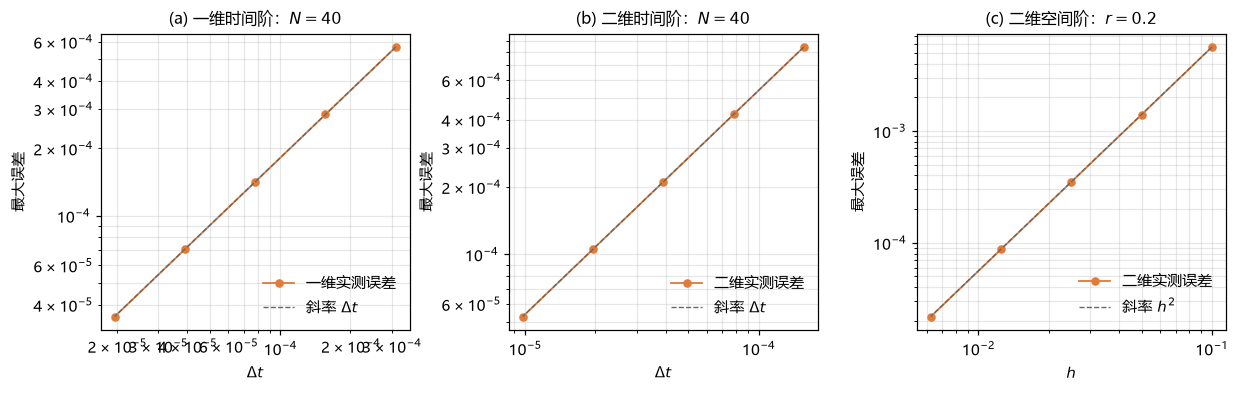

已保存 数据/表2-4-一维时间收敛.csv、数据/表2-6-二维时间收敛.csv


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.5), gridspec_kw={"wspace": 0.32})

ax = axes[0]
dts = np.array([row["dt"] for row in rows1t]); es = np.array([row["err"] for row in rows1t])
ax.loglog(dts, es, "o-", color=ORANGE, lw=1.2, ms=4.6, label="一维实测误差")
ax.loglog(dts, es[0] * (dts / dts[0]), "--", color=GRAY, lw=0.9, label=r"斜率 $\Delta t$")
ax.set_xlabel(r"$\Delta t$"); ax.set_ylabel("最大误差")
ax.set_title(r"(a) 一维时间阶：$N=40$", fontsize=10.5)
ax.grid(alpha=.3, which="both"); ax.legend(loc="lower right")

ax = axes[1]
dts = np.array([row["dt"] for row in rows2t]); es = np.array([row["err"] for row in rows2t])
ax.loglog(dts, es, "o-", color=ORANGE, lw=1.2, ms=4.6, label="二维实测误差")
ax.loglog(dts, es[0] * (dts / dts[0]), "--", color=GRAY, lw=0.9, label=r"斜率 $\Delta t$")
ax.set_xlabel(r"$\Delta t$"); ax.set_ylabel("最大误差")
ax.set_title(r"(b) 二维时间阶：$N=40$", fontsize=10.5)
ax.grid(alpha=.3, which="both"); ax.legend(loc="lower right")

ax = axes[2]
hs = np.array([row["h"] for row in rows2]); es = np.array([row["err"] for row in rows2])
ax.loglog(hs, es, "o-", color=ORANGE, lw=1.2, ms=4.6, label="二维实测误差")
ax.loglog(hs, es[0] * (hs / hs[0]) ** 2, "--", color=GRAY, lw=0.9, label=r"斜率 $h^2$")
ax.set_xlabel("$h$"); ax.set_ylabel("最大误差")
ax.set_title(r"(c) 二维空间阶：$r=0.2$", fontsize=10.5)
ax.grid(alpha=.3, which="both"); ax.legend(loc="lower right")

fig.savefig("图片/图2-5-二维空间阶与时间阶.png", facecolor="white")
plt.show()

with open("数据/表2-4-一维时间收敛.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("r,dt,M,err,p\n")
    for row in rows1t:
        fp.write(f"{row['r']:.6f},{row['dt']:.6e},{row['M']},{row['err']:.6e},"
                 f"{'' if row['p'] is None else round(row['p'], 2)}\n")
with open("数据/表2-6-二维时间收敛.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("r,dt,M,err,p\n")
    for row in rows2t:
        fp.write(f"{row['r']:.6f},{row['dt']:.6e},{row['M']},{row['err']:.6e},"
                 f"{'' if row['p'] is None else round(row['p'], 2)}\n")
print("已保存 数据/表2-4-一维时间收敛.csv、数据/表2-6-二维时间收敛.csv")

#### 稳定性门槛：放大因子与阈值扫描

一维放大因子 $g(\theta)=1-4r\sin^2(\theta/2)$；最危险的是 $\theta=\pi$（相邻节点正负交替），$|g(\pi)|=|1-4r|$。
下面画 $g(\theta)$ 与 $\max_\theta|g|$，再让 $r$ 跨过 $1/2$ 做扫描：在初值上加一个 $10^{-3}$ 的网格尺度扰动，
扰动前后的两个解相减，就单独得到这个高频模态。

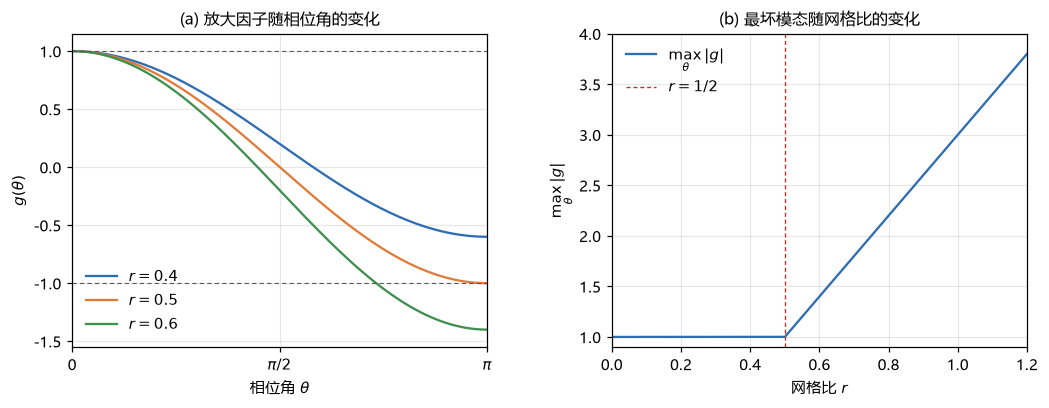

In [18]:
theta = np.linspace(0, np.pi, 400)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.7), gridspec_kw={"wspace": 0.3})

ax = axes[0]
for rr, c in zip((0.4, 0.5, 0.6), (BLUE, ORANGE, GREEN)):
    ax.plot(theta, 1 - 4 * rr * np.sin(theta / 2) ** 2, color=c, lw=1.5, label=rf"$r={rr}$")
ax.axhline(1, color="#555555", lw=0.7, ls=(0, (4, 3)))
ax.axhline(-1, color="#555555", lw=0.7, ls=(0, (4, 3)))
ax.set_xlabel(r"相位角 $\theta$"); ax.set_ylabel(r"$g(\theta)$")
ax.set_xticks([0, np.pi / 2, np.pi]); ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$"])
ax.set_xlim(0, np.pi); ax.set_ylim(-1.55, 1.15)
ax.legend(loc="lower left"); ax.grid(alpha=.3)
ax.set_title("(a) 放大因子随相位角的变化", fontsize=10.5)

ax = axes[1]
rr = np.linspace(0, 1.2, 500)
ax.plot(rr, np.maximum(1, np.abs(1 - 4 * rr)), color=BLUE, lw=1.5, label=r"$\max_\theta |g|$")
ax.axvline(0.5, color=RED, lw=0.9, ls=(0, (3, 2)), label=r"$r=1/2$")
ax.set_xlabel(r"网格比 $r$"); ax.set_ylabel(r"$\max_\theta |g|$")
ax.set_xlim(0, 1.2); ax.set_ylim(0.9, 4.0)
ax.legend(loc="upper left"); ax.grid(alpha=.3)
ax.set_title("(b) 最坏模态随网格比的变化", fontsize=10.5)

fig.savefig("图片/图3-1-放大因子.png", facecolor="white")
plt.show()

In [20]:
def growth_1d(N, r_target, T, amp=1e-3):
    x = np.linspace(0, 1, N + 1)
    smooth = np.sin(np.pi * x)
    bump = amp * np.sin((N - 1) * np.pi * x)
    _, Ua, M, dt, r_eff = solve1d(N, r_target, T, u0=smooth)
    _, Ub, _, _, _ = solve1d(N, r_target, T, u0=smooth + bump)
    th = (N - 1) * np.pi / N
    g = 1 - 4 * r_eff * np.sin(th / 2) ** 2
    return dict(r=r_eff, M=M, dt=dt, g_pi=1 - 4 * r_eff, g_th=g,
                theory=abs(g) ** M, meas=np.max(np.abs(Ub - Ua)) / amp,
                Ua=Ua, Ub=Ub, exact=np.exp(-np.pi ** 2 * T) * smooth)


T, N = 0.05, 20
tab = [growth_1d(N, rt, T) for rt in (0.40, 0.45, 0.50, 0.55, 0.60)]
print(f"{'目标r':>6}{'实际r':>8}{'M':>4}{'|g(pi)|':>9}{'理论增长':>12}{'实测增长':>12}{'判定':>6}")
for row in tab:
    verdict = "稳定" if abs(row["g_pi"]) <= 1 else "失稳"
    print(f"{row['r']:>6.4f}{row['r']:>8.4f}{row['M']:>4}{abs(row['g_pi']):>9.3f}"
          f"{row['theory']:>12.3e}{row['meas']:>12.3e}{verdict:>6}")

with open("数据/表3-2-网格比扫描.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("r,M,g_pi,g_theta,theory,meas,verdict\n")
    for row in tab:
        fp.write(f"{row['r']:.4f},{row['M']},{abs(row['g_pi']):.3f},{abs(row['g_th']):.4f},"
                 f"{row['theory']:.3e},{row['meas']:.3e},{'稳定' if abs(row['g_pi']) <= 1 else '失稳'}\n")
print("已保存 数据/表3-2-网格比扫描.csv")

   目标r     实际r   M  |g(pi)|        理论增长        实测增长    判定
0.4000  0.4000  50    0.600   3.533e-12   3.664e-12    稳定
0.4545  0.4545  44    0.818   7.983e-05   7.983e-05    稳定
0.5000  0.5000  40    1.000   6.093e-01   6.093e-01    稳定
0.5556  0.5556  36    1.222   9.150e+02   9.150e+02    失稳
0.6061  0.6061  33    1.424   8.266e+04   8.266e+04    失稳
已保存 数据/表3-2-网格比扫描.csv


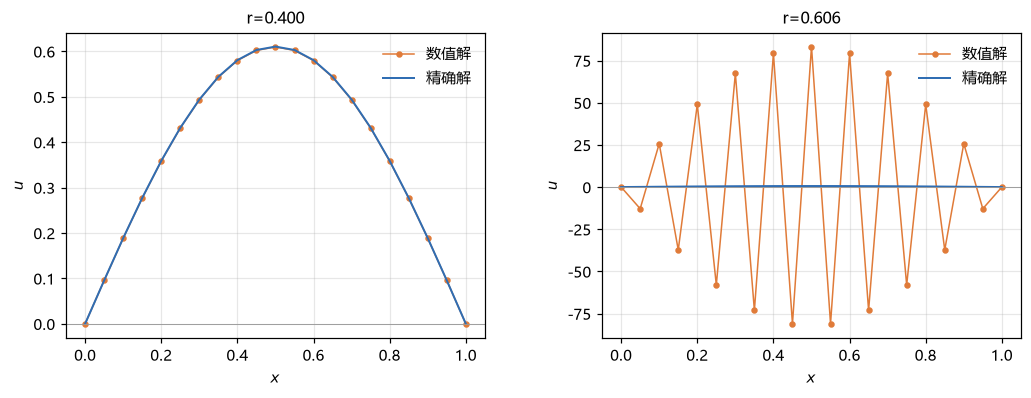

r=0.606 时数值解范围：min = -81.0  max = 83.3 ；变号次数 = 18


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6), gridspec_kw={"wspace": 0.28})
for ax, row, tag in ((axes[0], tab[0], "r=0.400"), (axes[1], tab[-1], "r=0.606")):
    x = np.linspace(0, 1, N + 1)
    ax.plot(x, row["Ub"], "o-", color=ORANGE, lw=1.0, ms=3.2, label="数值解")
    ax.plot(x, row["exact"], "-", color=BLUE, lw=1.3, label="精确解")
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_xlabel("$x$"); ax.set_ylabel("$u$")
    ax.set_title(tag, fontsize=10.5); ax.legend(loc="upper right"); ax.grid(alpha=.3)
fig.savefig("图片/图3-2-失稳形态.png", facecolor="white")
plt.show()

print("r=0.606 时数值解范围：min =", f"{tab[-1]['Ub'].min():.1f}", " max =", f"{tab[-1]['Ub'].max():.1f}",
      "；变号次数 =", int(np.sum(np.sign(tab[-1]['Ub'][1:-1])[1:] != np.sign(tab[-1]['Ub'][1:-1])[:-1])))

#### 网格加密的代价

固定 $\Delta t$ 加密网格，$r$ 会随 $h^{-2}$ 增大，很快越过稳定上界；要保持 $r=1/2$，必须让 $\Delta t\propto h^2$，
时间步数随 $N^2$ 增长。下面把这两件事画在一起。

In [22]:
# (1) 固定 dt=0.002、T=0.02 加密网格
rows_dt = []
for N in (10, 20, 40, 80):
    h = 1.0 / N
    dt = 0.002
    M = int(round(0.02 / dt))
    dt = 0.02 / M
    r_eff = dt / h ** 2
    x = np.linspace(0, 1, N + 1)
    U = np.sin(np.pi * x) + 1e-3 * np.sin((N - 1) * np.pi * x)
    U[0] = U[-1] = 0.0
    for _ in range(M):
        U[1:-1] = U[1:-1] + r_eff * (U[:-2] - 2 * U[1:-1] + U[2:])
        U[0] = U[-1] = 0.0
    rows_dt.append(dict(N=N, h=h, r=r_eff, maxabs=np.max(np.abs(U))))
    print(f"N={N:>3}  h={h:.3e}  r={r_eff:6.2f}  max|U|={np.max(np.abs(U)):.3e}")

# (2) 保持 r=1/2、T=0.1
rows_half = []
for N in (10, 20, 40, 80, 160):
    h = 1.0 / N
    dt = h * h / 2.0
    M = int(round(0.1 / dt))
    rows_half.append(dict(N=N, h=h, dt=dt, M=M))
    print(f"N={N:>3}  h={h:.3e}  dt={dt:.3e}  M={M}")

N= 10  h=1.000e-01  r=  0.20  max|U|=8.206e-01
N= 20  h=5.000e-02  r=  0.80  max|U|=3.207e+00
N= 40  h=2.500e-02  r=  3.20  max|U|=5.147e+07
N= 80  h=1.250e-02  r= 12.80  max|U|=1.012e+14
N= 10  h=1.000e-01  dt=5.000e-03  M=20
N= 20  h=5.000e-02  dt=1.250e-03  M=80
N= 40  h=2.500e-02  dt=3.125e-04  M=320
N= 80  h=1.250e-02  dt=7.813e-05  M=1280
N=160  h=6.250e-03  dt=1.953e-05  M=5120


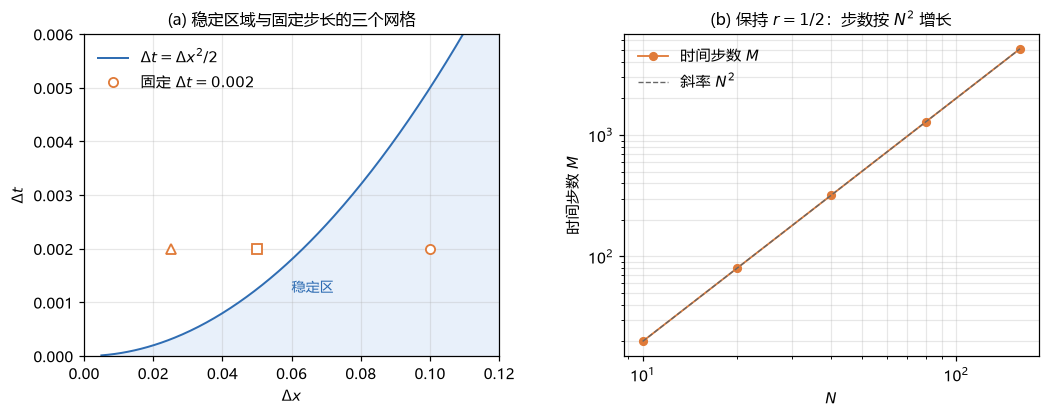

双对数下 M 对 N 的斜率 = 2.000


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.8), gridspec_kw={"wspace": 0.3})

ax = axes[0]
dx = np.linspace(0.005, 0.12, 300)
ax.fill_between(dx, 0, dx ** 2 / 2, color="#e8f0fa")
ax.plot(dx, dx ** 2 / 2, color=BLUE, lw=1.3, label=r"$\Delta t=\Delta x^2/2$")
for N, mk in ((10, "o"), (20, "s"), (40, "^")):
    ax.plot([1.0 / N], [0.002], mk, ms=6, mfc="white", mec=ORANGE, mew=1.2, zorder=5,
            label=r"固定 $\Delta t=0.002$" if N == 10 else None)
ax.set_xlabel(r"$\Delta x$"); ax.set_ylabel(r"$\Delta t$")
ax.set_xlim(0, 0.12); ax.set_ylim(0, 0.006)
ax.text(0.06, 0.0012, "稳定区", fontsize=9, color=BLUE)
ax.legend(loc="upper left"); ax.grid(alpha=.3)
ax.set_title("(a) 稳定区域与固定步长的三个网格", fontsize=10.5)

ax = axes[1]
Ns = np.array([row["N"] for row in rows_half]); Ms = np.array([row["M"] for row in rows_half])
ax.loglog(Ns, Ms, "o-", color=ORANGE, lw=1.2, ms=5, label="时间步数 $M$")
ax.loglog(Ns, Ms[0] * (Ns / Ns[0]) ** 2, "--", color=GRAY, lw=0.9, label=r"斜率 $N^2$")
ax.set_xlabel("$N$"); ax.set_ylabel("时间步数 $M$")
ax.legend(loc="upper left"); ax.grid(alpha=.3, which="both")
ax.set_title(r"(b) 保持 $r=1/2$：步数按 $N^2$ 增长", fontsize=10.5)

fig.savefig("图片/图3-3-网格加密的代价.png", facecolor="white")
plt.show()

slope = (math.log(Ms[-1]) - math.log(Ms[0])) / (math.log(Ns[-1]) - math.log(Ns[0]))
print(f"双对数下 M 对 N 的斜率 = {slope:.3f}")

#### 二维的门槛：$r\le1/4$

二维的最危险模态是"棋盘格"，放大因子 $1-8r$，门槛 $r\le1/4$。用棋盘格扰动对比 $r=0.25$ 与 $r=0.26$。

In [24]:
N = 20
checker = lambda X, Y, N=N: 1e-3 * np.cos((N - 1) * np.pi * X) * np.cos((N - 1) * np.pi * Y)
for rt in (0.25, 0.26):
    x, X, Y, U, M, dt, r_eff = solve2d(N, rt, 0.05, x0=checker)
    print(f"目标 r={rt:.2f}  实际 r={r_eff:.4f}  M={M}  g=1-8r={1 - 8 * r_eff:.4f}  "
          f"max|U|={np.max(np.abs(U)):.3e}  估计增长 {abs(1 - 8 * r_eff) ** M:.2e}")

目标 r=0.25  实际 r=0.2500  M=80  g=1-8r=-1.0000  max|U|=1.000e-03  估计增长 1.00e+00
目标 r=0.26  实际 r=0.2597  M=77  g=1-8r=-1.0779  max|U|=5.675e-03  估计增长 3.23e+02


### 小结

- 正文式 (5) 在代码里是一行 `U[1:-1] = U[1:-1] + r*(U[:-2] - 2*U[1:-1] + U[2:])`；**步长必须取整后修正**，否则最后一层不在 $T$ 上、实际 $r$ 与名义值不符。
- 系数矩阵 $A$ 的内部行永远是 $(-r,\ 1+2r,\ -r)$，三种边界条件只改首末两行与 $\boldsymbol b$ 的首末分量（表 2-1）；二维按行优先排序后得到块三对角矩阵，内部行五个非零元（表 2-2）。
- 一维、二维的空间阶都是 2.00，时间阶都是 1.00；同步加密时看到 2 是"时空共同阶"，不是时间也二阶。
- 稳定上界 $r\le1/2$（一维）、$r\le1/4$（二维）在本文件中用四条途径复现：负权重、放大因子、实测增长倍数、二维棋盘格扰动。

**输出位置**：图片 → `图片/图2-1-…`、`图片/图2-3-…`、`图片/图2-4-…`、`图片/图2-5-…`、`图片/图3-1-…`、`图片/图3-2-…`、`图片/图3-3-…`；数据 → `数据/表2-3-…csv`、`数据/表2-4-…csv`、`数据/表2-5-…csv`、`数据/表2-6-…csv`、`数据/表3-2-…csv`。

In [25]:
summary = dict(
    space_order_1d=[(row["N"], row["err"], row["p"]) for row in rows],
    space_order_2d=[(row["N"], row["err"], row["p"]) for row in rows2],
    time_order_1d=[(row["r"], row["err"], row["p"]) for row in rows1t],
    time_order_2d=[(row["r"], row["err"], row["p"]) for row in rows2t],
    stability_sweep=[(row["r"], abs(row["g_pi"]), row["theory"], row["meas"]) for row in tab],
    grid_half=[(row["N"], row["dt"], row["M"]) for row in rows_half],
)
with open("数据/ch3_2_results.json", "w", encoding="utf-8") as fp:
    json.dump(summary, fp, ensure_ascii=False, indent=1)
print("已保存 数据/ch3_2_results.json")
print("图片目录:", sorted(f for f in os.listdir("图片") if f.startswith(("图2-", "图3-"))))

已保存 数据/ch3_2_results.json
图片目录: ['图2-1-一维网格与模板.png', '图2-2-二维五点模板.png', '图2-3-一维数值解与空间阶.png', '图2-4-二维数值解与误差场-3D.png', '图2-4-二维数值解与误差场.png', '图2-5-二维空间阶与时间阶.png', '图3-1-放大因子.png', '图3-2-失稳形态.png', '图3-3-网格加密的代价.png']


---

> **本节来源**：`A1-G3-3.3实验.ipynb`（原内核 `python3`，Python 3.12.10；15 个单元，其中 7 个代码单元）。代码与输出保持原样；本节标题块里的“本文件 / 配套文件”保留原 Notebook 说明，便于对照。

## 3.3　有限元：弱形式与 Galerkin 方法 · 实验

> A1-G3 · 第03章 · 3.3 节  
> 与 `A1-G3-正文.md` 的 3.3 节配套；按 3.3.1–3.3.3 组织。  
> 环境：Python 3.12.10、NumPy 2.x、Matplotlib 3.11；固定种子 2026。  
> 输出：`图片/A1-G3-3.3-实验-*.png`、`数据/A1-G3-3.3-*.csv`。

**实验设计（先预测，再运行）**

| 项目 | 内容 |
| --- | --- |
| 问题与预测 | 线性元 $L^2$ 二阶、$H^1$ 一阶；求积不足破坏节点精确；界面错位会破坏收敛阶。 |
| 输入与参数 | 一维 Poisson，$u(0)=u(1)=0$；$u=\sin(\pi x)$；$N=8,\dots,128$；$a=1+0.5x$；界面 $x=0.5$ / $0.53$。 |
| 参考解 | 解析解；差分矩阵交叉核对。 |
| 误差与容差 | $L^2$、$H^1$ 半范数，$p=\log_2(e_h/e_{h/2})$；节点误差容差 $10^{-12}$。 |
| 环境与预算 | 见上；单次运行 < 10 s。 |


In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", message=".*glyph.*")

np.random.seed(2026)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["SimSun", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
    "figure.dpi": 120,
})

IMG = Path("图片"); DAT = Path("数据")
IMG.mkdir(exist_ok=True); DAT.mkdir(exist_ok=True)

GL = {
    1: (np.array([0.0]), np.array([2.0])),
    2: (np.array([-1/np.sqrt(3), 1/np.sqrt(3)]), np.array([1.0, 1.0])),
    4: (np.array([-0.8611363115940526, -0.3399810435848563,
                  0.3399810435848563, 0.8611363115940526]),
        np.array([0.3478548451374538, 0.6521451548625461,
                  0.6521451548625461, 0.3478548451374538])),
}


def mesh(N):
    return np.linspace(0.0, 1.0, N + 1)


def assemble(x, a=lambda t: 1.0, f=lambda t: 1.0, ngauss=4):
    N = len(x) - 1
    K = np.zeros((N + 1, N + 1))
    F = np.zeros(N + 1)
    xi, w = GL[ngauss]
    for e in range(N):
        h = x[e + 1] - x[e]
        am = a(0.5 * (x[e] + x[e + 1]))
        K[e:e + 2, e:e + 2] += am / h * np.array([[1.0, -1.0], [-1.0, 1.0]])
        for q, wq in zip(xi, w):
            xx = 0.5 * (x[e] + x[e + 1]) + 0.5 * h * q
            phi = np.array([(1 - q) / 2, (1 + q) / 2])
            F[e:e + 2] += 0.5 * h * wq * f(xx) * phi
    return K, F


def solve(K, F):
    u = np.zeros(len(F))
    u[1:-1] = np.linalg.solve(K[1:-1, 1:-1], F[1:-1])
    return u


def errors(x, u, ue, due):
    N = len(x) - 1
    xi, w = GL[4]
    l2 = h1 = 0.0
    for e in range(N):
        h = x[e + 1] - x[e]
        du = (u[e + 1] - u[e]) / h
        for q, wq in zip(xi, w):
            xx = 0.5 * (x[e] + x[e + 1]) + 0.5 * h * q
            uh = u[e] * (1 - q) / 2 + u[e + 1] * (1 + q) / 2
            l2 += 0.5 * h * wq * (ue(xx) - uh) ** 2
            h1 += 0.5 * h * wq * (due(xx) - du) ** 2
    return np.sqrt(l2), np.sqrt(h1)


def rate(e1, e2):
    return np.log2(e1 / e2)

print("环境就绪：", np.__version__, plt.matplotlib.__version__)


环境就绪： 2.5.4 3.11.2


### 3.3.1　弱形式与帽函数

一维模型问题

$$
-u''=f,\quad 0<x<1,\qquad u(0)=u(1)=0.
$$

乘以检验函数 $v$、分部积分，得到弱形式：求 $u\in H^1_0$，使

$$
\int_0^1 u'v'\,\mathrm{d}x=\int_0^1 fv\,\mathrm{d}x
$$

对一切 $v\in H^1_0$ 成立。把 $[0,1]$ 分成 $N$ 个单元，节点 $x_i=ih$，帽函数 $\varphi_i$ 在 $x_i$ 取 1、在相邻节点取 0。下面画出其中一个帽函数，并核对“帽函数之和为 1”。


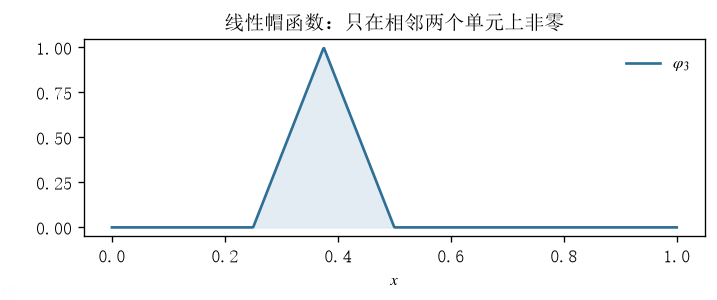

帽函数之和的最大偏差： 0.0
单元刚度矩阵 (h=1/8)：
 [[ 8. -8.]
 [-8.  8.]]
行和（应约为 0）： [0. 0.]


In [2]:
N = 8
x = mesh(N)
h = 1.0 / N

fig, ax = plt.subplots(figsize=(6.0, 2.6))
xx = np.linspace(0, 1, 800)
i = 3
phi = np.maximum(0.0, 1.0 - np.abs(xx - x[i]) / h)
ax.plot(xx, phi, color="#2E6F95", lw=1.6, label=fr"$\varphi_{i}$")
ax.fill_between(xx, 0, phi, color="#DCE8F0", alpha=0.8)
ax.set_xlabel("$x$"); ax.set_ylabel("帽函数")
ax.set_title("线性帽函数：只在相邻两个单元上非零")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "A1-G3-3.3-实验-帽函数.png", facecolor="white")
plt.show()

# 单位分解
S = np.zeros_like(xx)
for j in range(N + 1):
    S += np.maximum(0.0, 1.0 - np.abs(xx - x[j]) / h)
print("帽函数之和的最大偏差：", np.max(np.abs(S - 1.0)))

# 一个单元的刚度矩阵
ke = (1.0 / h) * np.array([[1.0, -1.0], [-1.0, 1.0]])
print("单元刚度矩阵 (h=1/8)：\n", ke)
print("行和（应约为 0）：", ke.sum(axis=1))


### 3.3.2　单元矩阵与装配

每个单元贡献 $2\times2$ 的 $\frac{a}{h}\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$，按节点编号累加。下面装配 $N=8$ 的总体矩阵，并与差分矩阵对照；再比较消元法、置 1 法与置大数法三种边界处理。

> 注意：矩阵相同只说明“这个一维常系数特例”相同；弱形式、载荷与边界项才是有限元的内容。


In [3]:
N = 8
x = mesh(N); h = 1.0 / N
K, F = assemble(x, f=lambda t: np.pi**2 * np.sin(np.pi * t))

# 差分矩阵（内部）
Kfd = np.zeros((N + 1, N + 1))
for e in range(N):
    Kfd[e:e+2, e:e+2] += (1.0 / h) * np.array([[1.0, -1.0], [-1.0, 1.0]])
print("FEM 与差分内部矩阵最大差：", np.max(np.abs(K[1:-1, 1:-1] - Kfd[1:-1, 1:-1])))

# 消元法
u_elim = solve(K, F)

# 置 1 法
K1 = K.copy(); F1 = F.copy()
for d in (0, N):
    K1[d, :] = 0; K1[:, d] = 0; K1[d, d] = 1.0; F1[d] = 0.0
u_one = np.linalg.solve(K1, F1)

# 置大数法
Kb = K.copy(); Fb = F.copy()
for d in (0, N):
    Kb[d, d] = 1e12; Fb[d] = 0.0
u_big = np.linalg.solve(Kb, Fb)

print("消元 vs 置1 最大差：", np.max(np.abs(u_elim - u_one)))
print("消元 vs 置大数 最大差：", np.max(np.abs(u_elim - u_big)))
print("内部矩阵条件数：", f"{np.linalg.cond(K[1:-1,1:-1]):.3e}")
print("置大数后条件数：", f"{np.linalg.cond(Kb[1:-1,1:-1]):.3e}")


FEM 与差分内部矩阵最大差： 0.0
消元 vs 置1 最大差： 0.0
消元 vs 置大数 最大差： 3.0617730573112567e-12
内部矩阵条件数： 2.527e+01
置大数后条件数： 2.527e+01


### 3.3.3　收敛阶：$L^2$ 与 $H^1$

取制造解 $u=\sin(\pi x)$，$f=\pi^2\sin(\pi x)$。对 $N=8,16,32,64,128$ 计算 $L^2$ 误差与 $H^1$ 半范数，用相邻两次的误差比估计观测阶。预测：$p_{L^2}\approx2$、$p_{H^1}\approx1$。


   N         L2         H1    pL2    pH1
   8  9.921e-03  2.512e-01    nan    nan
  16  2.487e-03  1.258e-01   2.00   1.00
  32  6.220e-04  6.295e-02   2.00   1.00
  64  1.555e-04  3.148e-02   2.00   1.00
 128  3.888e-05  1.574e-02   2.00   1.00


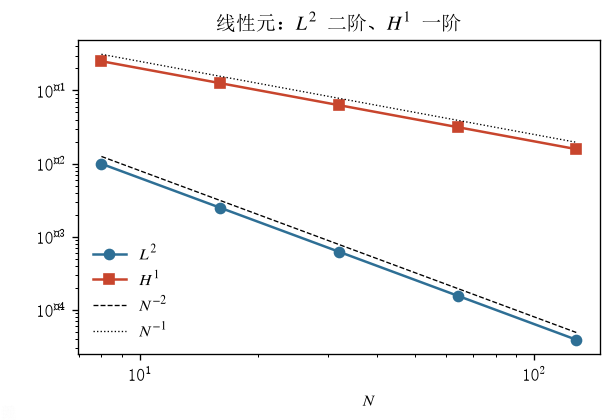

In [4]:
ue = lambda t: np.sin(np.pi * t)
due = lambda t: np.pi * np.cos(np.pi * t)
f = lambda t: np.pi**2 * np.sin(np.pi * t)

rows = []
prev = None
for N in (8, 16, 32, 64, 128):
    x = mesh(N)
    K, F = assemble(x, f=f)
    u = solve(K, F)
    eL2, eH1 = errors(x, u, ue, due)
    if prev is None:
        rows.append((N, eL2, eH1, np.nan, np.nan))
    else:
        rows.append((N, eL2, eH1, rate(prev[0], eL2), rate(prev[1], eH1)))
    prev = (eL2, eH1)

print(f"{'N':>4} {'L2':>10} {'H1':>10} {'pL2':>6} {'pH1':>6}")
for N, a1, a2, p1, p2 in rows:
    print(f"{N:>4} {a1:10.3e} {a2:10.3e} {p1:6.2f} {p2:6.2f}")

np.savetxt(DAT / "A1-G3-3.3-收敛阶.csv", np.array(rows), delimiter=",",
           header="N,L2,H1,pL2,pH1", comments="")

fig, ax = plt.subplots(figsize=(5.2, 3.6))
Ns = np.array([r[0] for r in rows], float)
ax.loglog(Ns, [r[1] for r in rows], "o-", color="#2E6F95", label=r"$L^2$")
ax.loglog(Ns, [r[2] for r in rows], "s-", color="#C8452D", label=r"$H^1$")
ax.loglog(Ns, 0.8 / Ns**2, "k--", lw=0.8, label=r"$N^{-2}$")
ax.loglog(Ns, 2.5 / Ns, "k:", lw=0.8, label=r"$N^{-1}$")
ax.set_xlabel("单元数 $N$"); ax.set_ylabel("误差")
ax.set_title("线性元：$L^2$ 二阶、$H^1$ 一阶")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "A1-G3-3.3-实验-收敛阶.png", facecolor="white")
plt.show()


### 3.3.4　求积不足会破坏节点精确

对 $-u''=f$、线性元，若载荷 $\int f\varphi_i$ 精确计算，节点值 $u_h(x_i)=u(x_i)$（节点超收敛）。下面分别用 4 点 Gauss（足够精确）和 1 点 Gauss 计算载荷，比较节点最大误差。预测：4 点达到舍入级，1 点只有 $O(h^2)$。


In [5]:
ue = lambda t: np.sin(np.pi * t)
f = lambda t: np.pi**2 * np.sin(np.pi * t)

print(f"{'N':>4} {'4点节点误差':>14} {'1点节点误差':>14}")
for N in (8, 16, 32, 64):
    x = mesh(N)
    K4, F4 = assemble(x, f=f, ngauss=4)
    u4 = solve(K4, F4)
    K1, F1 = assemble(x, f=f, ngauss=1)
    u1 = solve(K1, F1)
    print(f"{N:>4} {np.max(np.abs(u4-ue(x))):14.3e} {np.max(np.abs(u1-ue(x))):14.3e}")


   N         4点节点误差         1点节点误差
   8      2.242e-12      6.513e-03
  16      8.438e-15      1.612e-03
  32      3.109e-15      4.019e-04
  64      9.104e-15      1.004e-04


### 3.3.5　变系数 $a(x)=1+0.5x$

取 $u=\sin(\pi x)$，则

$$
f=-(a u')'=-0.5\pi\cos(\pi x)+(1+0.5x)\pi^2\sin(\pi x).
$$

单元刚度用中点 $a$ 近似。若 $a$ 光滑、求积足够，收敛阶应保持 2/1。


In [6]:
a = lambda t: 1 + 0.5 * t
fc = lambda t: -0.5*np.pi*np.cos(np.pi*t) + (1+0.5*t)*np.pi**2*np.sin(np.pi*t)

prev = None
print(f"{'N':>4} {'L2':>10} {'H1':>10} {'pL2':>6} {'pH1':>6}")
for N in (8, 16, 32, 64, 128):
    x = mesh(N)
    K, F = assemble(x, a=a, f=fc)
    u = solve(K, F)
    eL2, eH1 = errors(x, u, ue, due)
    if prev:
        print(f"{N:>4} {eL2:10.3e} {eH1:10.3e} {rate(prev[0],eL2):6.2f} {rate(prev[1],eH1):6.2f}")
    else:
        print(f"{N:>4} {eL2:10.3e} {eH1:10.3e} {'-':>6} {'-':>6}")
    prev = (eL2, eH1)


   N         L2         H1    pL2    pH1
   8  9.884e-03  2.512e-01      -      -
  16  2.477e-03  1.258e-01   2.00   1.00
  32  6.196e-04  6.295e-02   2.00   1.00
  64  1.549e-04  3.148e-02   2.00   1.00
 128  3.873e-05  1.574e-02   2.00   1.00


### 3.3.6　界面失配

两根材料 $a_1=1$（$x<x_i$）、$a_2=2$（$x>x_i$），受均布载荷 $f=1$。精确解是分段二次：

$$
u_1=-\frac{x^2}{2a_1}+Bx,\qquad
u_2=-\frac{x^2}{2a_2}+Dx+E,
$$

由 $u(0)=u(1)=0$、界面连续与通量连续 $a_1u_1'=a_2u_2'$ 定出 $B,D,E$。比较界面与节点对齐（$x_i=0.5$）和错位（$x_i=0.53$）。



界面 xi=0.5，B=0.416667, D=0.208333
   N         L2         H1    pL2    pH1
   8  1.128e-03  2.853e-02      -      -
  16  2.819e-04  1.426e-02   2.00   1.00
  32  7.048e-05  7.132e-03   2.00   1.00
  64  1.762e-05  3.566e-03   2.00   1.00
 128  4.405e-06  1.783e-03   2.00   1.00

界面 xi=0.53，B=0.418595, D=0.209297
   N         L2         H1    pL2    pH1
   8  1.397e-03  2.838e-02      -      -
  16  6.300e-04  1.588e-02   1.15   0.84
  32  6.286e-05  7.265e-03   3.33   1.13
  64  1.968e-05  4.426e-03   1.68   0.71
 128  2.003e-05  2.655e-03  -0.03   0.74


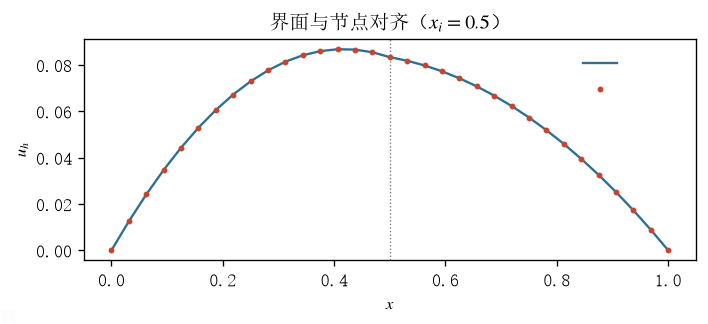

In [7]:
a1, a2 = 1.0, 2.0

def interface_case(xi):
    D = (1/(2*a2) + xi**2/(2*a1) - xi**2/(2*a2)) / ((a2/a1)*xi - xi + 1)
    B = (a2/a1) * D
    E = 1/(2*a2) - D
    uex = lambda t: np.where(t < xi, -t**2/(2*a1) + B*t, -t**2/(2*a2) + D*t + E)
    duex = lambda t: np.where(t < xi, -t/a1 + B, -t/a2 + D)
    ax = lambda t: np.where(t < xi, a1, a2)
    return B, D, uex, duex, ax

for xi in (0.5, 0.53):
    B, D, uex, duex, ax = interface_case(xi)
    print(f"\n界面 xi={xi}，B={B:.6f}, D={D:.6f}")
    print(f"{'N':>4} {'L2':>10} {'H1':>10} {'pL2':>6} {'pH1':>6}")
    prev = None
    for N in (8, 16, 32, 64, 128):
        x = mesh(N)
        K, F = assemble(x, a=ax, f=lambda t: 1.0)
        u = solve(K, F)
        eL2, eH1 = errors(x, u, uex, duex)
        if prev:
            print(f"{N:>4} {eL2:10.3e} {eH1:10.3e} {rate(prev[0],eL2):6.2f} {rate(prev[1],eH1):6.2f}")
        else:
            print(f"{N:>4} {eL2:10.3e} {eH1:10.3e} {'-':>6} {'-':>6}")
        prev = (eL2, eH1)

# 对齐时的解与误差示意
xi = 0.5
B, D, uex, duex, ax = interface_case(xi)
N = 32; x = mesh(N)
K, F = assemble(x, a=ax, f=lambda t: 1.0)
u = solve(K, F)
fig, axp = plt.subplots(figsize=(6.0, 2.8))
axp.plot(x, uex(x), color="#2E6F95", lw=1.4, label="精确解")
axp.plot(x, u, "o", ms=2.5, color="#C8452D", label="有限元")
axp.axvline(xi, color="#777777", ls=":", lw=0.8)
axp.set_xlabel("$x$"); axp.set_ylabel("$u_h$")
axp.set_title("界面与节点对齐（$x_i=0.5$）")
axp.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMG / "A1-G3-3.3-实验-界面.png", facecolor="white")
plt.show()


### 实验运行记录

| 项目 | 内容 |
| --- | --- |
| 日期 | 2026-10-25 |
| 环境 | Python 3.12.10、NumPy 2.x、Matplotlib 3.11 |
| 运行方式 | Kernel → Restart Kernel and Run All Cells（或 `jupyter nbconvert --execute`） |
| 随机种子 | 2026（问题本身无随机性，固定种子只为记录） |
| 输出 | `图片/A1-G3-3.3-实验-*.png`；`数据/A1-G3-3.3-收敛阶.csv` |
| 结论 | 常系数与变系数：$L^2\\approx2$、$H^1\\approx1$；1 点求积破坏节点精确；界面错位后收敛阶变差 |
| 未验证 | B/C 复现；二维三角形与条件数未纳入本节实验 |
| AI 使用 | 代码由 AI 起草，组内需逐行核对并实际运行；见 `A1-G3-AI对话记录.md` |

**正式提交前必须做的事**：由组员在本机从头运行一遍，核对上表数字与正文表格；任何与正文不一致的地方，以实际运行结果为准改正文，不能改输出。


---

> **本节来源**：`A1-G3-3.4-实验-v4.ipynb`（原内核 `python3`，Python 3.11；22 个单元，其中 13 个代码单元）。代码未改动；执行输出为本稿补跑所得（原文件为空），补跑环境见封面；本节标题块里的“本文件 / 配套文件”保留原 Notebook 说明，便于对照。

## 3.4　实验：Neural ODE 与 PINN 的数值实验

本 Notebook 与正文 `A1-G3-3.4-正文` 一一对应，界面里出现的每个数字都能在正文中找到。
（图片文件名沿用初版编号，正文图号已按新顺序重排；文件名只影响覆盖哪个文件，不影响引用。）

正文图号对照：

| 实验 | 内容 | 对应正文 |
| --- | --- | --- |
| 一 | 一步反解 $\theta$：Euler 与 RK4 的差别 | §1.4、表 1、图 14 |
| 二 | $\theta$ 随步长收敛：Euler 是一阶方法 | §1.4、图 15 |
| 三 | 残差与配点：*残差小* 不等于 *解对* | §2.2、小实验 1、图 18 |
| 四 | logistic 数据反演向量场 | 第四章、图 25、图 28 |
| 五 | 三换验证：换初值、换步长 | §3.2、§3.3、表 2 |
| 六 | 表示能力与梯度成本：两笔“AI 的账” | §1.1、§1.3、图 6 右、图 11 |
| 七 | 权重偏科与学习率稳定域 | §2.3、§3.4、图 19、图 26 |

**环境**：Python 3.9+ 与 `numpy`、`matplotlib`。不需要 GPU，也不需要深度学习框架——
本章的网络只取线性形式 $f_\theta=-\theta u$，所以每个数都能手算核对。

```bash
pip install numpy matplotlib
```

**运行**：从上到下依次执行。图片写到同目录的 `图片/`，文件名与正文插图一致，可直接替换。

**字体**：图里中文用宋体、西文用 Times New Roman（Windows 自带）。其他系统请把下面的
`FONTS` 换成已装字体，例如 `["DejaVu Serif", "PingFang SC"]`。

In [1]:
# ---------------------------------------------------------------- 运行环境
import os

import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, NullLocator

FONTS = ["Times New Roman", "SimSun"]          # 西文、中文
plt.rcParams.update({
    "font.family": FONTS,
    "font.size": 9,
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
    "axes.edgecolor": "#4d4d4d",
    "axes.linewidth": 0.85,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.2,
    "legend.framealpha": 0.95,
    "legend.edgecolor": "#d9dde2",
    "figure.dpi": 120,
    "savefig.dpi": 400,          # 印刷用，正文按 0.7 倍版心宽排版
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.035,
    "savefig.facecolor": "white",
})

NAVY, BRICK, INK, GRAY, GRID = "#2b5f8e", "#b5432f", "#1d1d1d", "#6e7378", "#c9d2dd"
OUT = "图片"                      # 与正文 图片/ 同名同址
os.makedirs(OUT, exist_ok=True)


def tidy(ax, grid="xy"):
    '''统一的坐标轴外观：去上右边框、浅色虚线网格。'''
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(direction="out", length=3.2, width=0.8, colors="#333333", pad=2.5)
    for axis in grid:
        ax.grid(True, axis=axis, color=GRID, lw=0.55, ls=(0, (3, 3)), alpha=0.85)
    ax.set_axisbelow(True)


def save(fig, name):
    path = os.path.join(OUT, name)
    fig.savefig(path)
    print("已保存", path)

### 实验一　一步反解出 $\theta$（表 1、图 14）

取 $u'=-u$、$u(0)=1$，真解 $e^{-t}$；只给一个观测点 $(0.5,\ 0.6065)$，网络限定为线性形式
$f_\theta(t,u)=-\theta u$。

- **前向 Euler** 走一步（$h=0.5$）：$u_1=1-0.5\theta$，令 $u_1=0.6065$，得 $\theta=0.787$。
- **经典 RK4** 走一步：放大因子 $R(z)=1-z+\frac{z^2}{2}-\frac{z^3}{6}+\frac{z^4}{24}$，$z=h\theta$；
  令 $R(z)=0.6065$ 反解 $z$，再除以 $h$。

两种积分器都能让训练点误差**恰好为 0**——因为 $\theta$ 本来就是从那个点反解出来的。
差别要到外推区（$t=2$）才显形。

In [2]:
OBS_T, OBS_U = 0.5, 0.6065          # 正文 §1.4 的观测点


def rk4_factor(z):
    '''经典 RK4 走一步的放大因子（对 u' = -θu 是 z 的四次多项式）。'''
    return 1 - z + z**2 / 2 - z**3 / 6 + z**4 / 24


def fit_theta_exp(h, method="euler"):
    '''反解 θ：用步长 h 走 OBS_T 之后正好落到观测值 0.6065。'''
    n = int(round(OBS_T / h))
    r = OBS_U ** (1.0 / n)                     # 这一步需要达到的放大因子
    if method == "euler":
        return (1.0 - r) / h
    lo, hi = 0.0, 1.2                          # R(z) 在 (0, 1.2) 上单调下降
    for _ in range(300):
        mid = 0.5 * (lo + hi)
        if rk4_factor(mid) > r:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi) / h


TRUE2 = np.exp(-2)                             # 真值 0.1353
print("表 1　同一步反解出的 θ 与它在 t=2 处的外推误差")
print("观测点 (0.5, 0.6065)，真值 e^-2 = %.4f\n" % TRUE2)

table1 = {}
for name, method in [("前向 Euler", "euler"), ("经典 RK4", "rk4")]:
    for h in (0.5, 0.25):
        th = fit_theta_exp(h, method)
        pred = np.exp(-2 * th)                 # 拟合出的连续模型在 t=2 的预测
        dev = (pred - TRUE2) / TRUE2 * 100
        table1[(name, h)] = (th, pred, dev)
        dev_txt = "%+.1f%%" % (0.0 if abs(dev) < 0.05 else dev)
        print(f"{name}  h={h:<6}θ={th:.4f}  训练点误差=0.0  "
              f"t=2 预测={pred:.4f}  偏差={dev_txt}")

表 1　同一步反解出的 θ 与它在 t=2 处的外推误差
观测点 (0.5, 0.6065)，真值 e^-2 = 0.1353

前向 Euler  h=0.5   θ=0.7870  训练点误差=0.0  t=2 预测=0.2072  偏差=+53.1%
前向 Euler  h=0.25  θ=0.8849  训练点误差=0.0  t=2 预测=0.1704  偏差=+25.9%
经典 RK4  h=0.5   θ=1.0009  训练点误差=0.0  t=2 预测=0.1351  偏差=-0.2%
经典 RK4  h=0.25  θ=1.0001  训练点误差=0.0  t=2 预测=0.1353  偏差=+0.0%


已保存 图片\A1-G3-3.4-图14.png


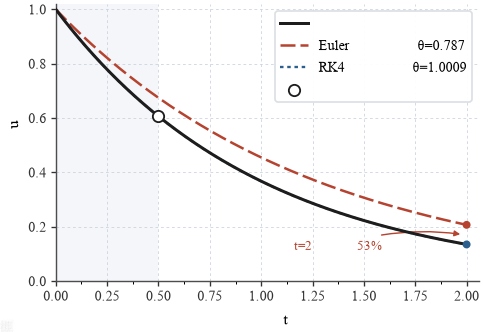

In [3]:
# ---------------------------------------------------------------- 图 18
th_e = fit_theta_exp(0.5, "euler")
th_r = fit_theta_exp(0.5, "rk4")
t = np.linspace(0, 2, 500)

fig, ax = plt.subplots(figsize=(4.55, 3.0))
ax.axvspan(0, 0.5, color=NAVY, alpha=0.05, lw=0, zorder=0)          # 训练所在区间
ax.plot(t, np.exp(-t), color=INK, lw=1.8, label="真解", zorder=4)
ax.plot(t, np.exp(-th_e * t), color=BRICK, lw=1.5, ls=(0, (6, 2)),
        label=f"Euler 训练模型  θ={th_e:.3f}", zorder=3)
ax.plot(t, np.exp(-th_r * t), color=NAVY, lw=1.4, ls=(0, (1.5, 1.6)),
        label=f"RK4 训练模型  θ={th_r:.4f}", zorder=3)

ax.scatter([0.5], [OBS_U], s=46, facecolors="white", edgecolors=INK,
           linewidths=1.1, zorder=6, label="观测点")
ax.text(0.25, 0.05, "训练区间", ha="center", fontsize=7.4, color=NAVY)
ax.scatter([2.0, 2.0], [np.exp(-2 * th_e), np.exp(-2 * th_r)], s=14,
           color=(BRICK, NAVY), zorder=6)
ax.annotate("t=2 处相差 53%", xy=(1.985, 0.171), xytext=(1.16, 0.115), fontsize=7.7,
            color=BRICK,
            arrowprops=dict(arrowstyle="-|>", color=BRICK, lw=0.85, mutation_scale=7,
                            connectionstyle="arc3,rad=-0.12"))

ax.set_xlim(0, 2.06)
ax.set_ylim(0, 1.02)
ax.set_xlabel("时间 t")
ax.set_ylabel("状态 u")
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
tidy(ax)
ax.legend(loc="upper right")
save(fig, "A1-G3-3.4-图14.png")
plt.show()

### 实验二　$\theta$ 随步长收敛（图 15）

固定用 Euler，把步长从 0.5 一路减半。若离散误差只是"噪声"，$\theta$ 应该乱跳；
实际它单调爬向 1，而且 $1-\theta$ 每减半步就减半——说明误差是**系统性**的，
并且与 $h$ 同阶（Euler 是一阶方法）。

h 与反解出的 θ
  h=0.5       θ=0.787000   1-θ=2.13e-01
  h=0.25      θ=0.884876   1-θ=1.15e-01
  h=0.125     θ=0.940114   1-θ=5.99e-02
  h=0.0625    θ=0.969486   1-θ=3.05e-02
  h=0.03125   θ=0.984634   1-θ=1.54e-02
  h=0.015625  θ=0.992328   1-θ=7.67e-03
已保存 图片\A1-G3-3.4-图15.png


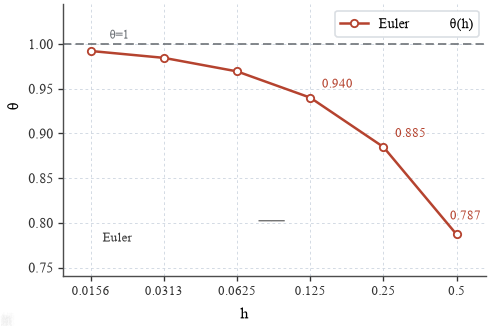

In [4]:
# ---------------------------------------------------------------- 图 15
hs = np.array([0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625])
th = np.array([fit_theta_exp(h, "euler") for h in hs])

print("h 与反解出的 θ")
for h, v in zip(hs, th):
    print(f"  h={h:<9} θ={v:.6f}   1-θ={1 - v:.2e}")

fig, ax = plt.subplots(figsize=(4.55, 2.95))
ax.axhline(1.0, color=GRAY, lw=1.0, ls=(0, (5, 2.5)), zorder=2)
ax.plot(hs, th, color=BRICK, lw=1.5, marker="o", ms=4.4, mfc="white", mew=1.1,
        zorder=4, label="Euler 反解  θ(h)")
for h, v, dx, dy in [(hs[0], th[0], -4, 9), (hs[1], th[1], 7, 6), (hs[2], th[2], 7, 6)]:
    ax.annotate(f"{v:.3f}", xy=(h, v), xytext=(dx, dy), textcoords="offset points",
                fontsize=7.5, color=BRICK)
ax.text(0.0142, 1.003, "真值 θ=1", fontsize=7.7, color=GRAY, va="bottom")
ax.text(0.0175, 0.775, "步长减半，偏差也随之减半——\nEuler 是一阶方法",
        fontsize=7.6, color="#3b3b3b", va="bottom", linespacing=1.5)

ax.set_xscale("log")
ax.set_xlim(0.012, 0.66)
ax.set_ylim(0.74, 1.045)
ax.set_xticks(hs)
ax.set_xticklabels(["0.5", "0.25", "0.125", "0.0625", "0.0313", "0.0156"], fontsize=7.6)
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel("步长 h（对数坐标）")
ax.set_ylabel("反解出的 θ")
tidy(ax)
ax.legend(loc="upper right")
save(fig, "A1-G3-3.4-图15.png")
plt.show()

### 实验三　残差与配点（图 18、小实验 1）

取 $u_\theta(t)=1+t$、方程 $u'=u$，则残差

$$r_\theta(t)=u_\theta'(t)-u_\theta(t)=1-(1+t)=-t .$$

**只要把一个配点放在 $t=0$，残差损失就是 0**；可它与真解 $e^{t}$ 的差却在 $t=1$ 处达到
$|2-e|\approx 0.718$。这就是"残差小"与"解对"之间的鸿沟。

配点上的残差（模型自认为的误差）与真实误差
  t=0.00   r=+0.000   |uθ-e^t|=0.0000
  t=0.25   r=-0.250   |uθ-e^t|=0.0340
  t=0.50   r=-0.500   |uθ-e^t|=0.1487
  t=0.75   r=-0.750   |uθ-e^t|=0.3670
  t=1.00   r=-1.000   |uθ-e^t|=0.7183

只取 t=0 一个配点时：残差损失 = 0.0，而 t=1 处的误差 = 0.718
已保存 图片\A1-G3-3.4-图18.png


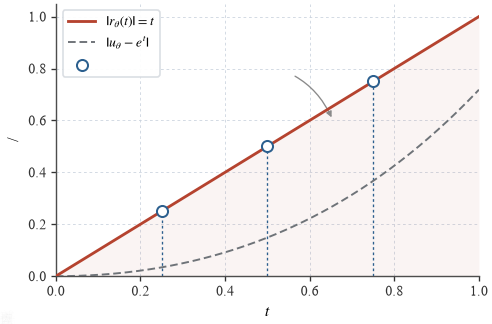

In [5]:
# ---------------------------------------------------------------- 图 18
print("配点上的残差（模型自认为的误差）与真实误差")
for tt in (0.0, 0.25, 0.5, 0.75, 1.0):
    print(f"  t={tt:4.2f}   r={1 - (1 + tt):+.3f}   |uθ-e^t|={abs((1 + tt) - np.exp(tt)):.4f}")
print("\n只取 t=0 一个配点时：残差损失 = 0.0，而 t=1 处的误差 = %.3f" % abs(2 - np.e))

t = np.linspace(0, 1, 400)
pts = np.array([0.25, 0.5, 0.75])
fig, ax = plt.subplots(figsize=(4.55, 2.95))
ax.fill_between(t, 0, t, color=BRICK, alpha=0.055, lw=0)
ax.plot(t, t, color=BRICK, lw=1.7, zorder=4, label="$|r_\\theta(t)|=t$")
ax.plot(t, np.abs(1 + t - np.exp(t)), color=GRAY, lw=1.15, ls=(0, (4, 2)),
        zorder=3, label="$|u_\\theta-e^{t}|$")
ax.vlines(pts, 0, pts, color=NAVY, lw=0.8, ls=(0, (2, 2)), zorder=2)
ax.scatter(pts, pts, s=44, facecolors="white", edgecolors=NAVY, linewidths=1.2,
           zorder=5, label="配点")
ax.annotate("配点之间可以为任意大", xy=(0.655, 0.60), xytext=(0.315, 0.80), fontsize=7.7,
            color="#3b3b3b",
            arrowprops=dict(arrowstyle="-|>", color="#8a8a8a", lw=0.8, mutation_scale=7,
                            connectionstyle="arc3,rad=-0.3"))
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.05)
ax.set_xlabel("$t$")
ax.set_ylabel("残差 / 误差")
tidy(ax)
ax.legend(loc="upper left")
save(fig, "A1-G3-3.4-图18.png")
plt.show()

### 实验四　logistic 数据反演向量场（图 25、图 28）

真模型取 $u'=ru(1-u/K)$，$r=0.8$、$K=1$、$u_0=0.05$；在 $t=0,0.1,\dots,2$ 上取 21 个点、
加 1% 的相对噪声。任务：只给这些点，把 $\theta=(r,K,u_0)$ 反演回来。

用**轨迹拟合**（正文式 (3)）：给定 $\theta$，用 RK4($h=0.1$) 积分出 $u_\theta(t_i)$，
最小化 $\sum_i (u_\theta(t_i)-u_i)^2$。三个参数用 Gauss–Newton 迭代（雅可比用差分数值算），
不依赖任何优化库。

> 提醒：观测窗口只到 $t=2$，曲线还没有明显"弯"，所以 $r$ 反演得很准（≈0.81），
> $K$ 则偏小（≈0.92）——**参数的可辨识性取决于数据覆盖了曲线的哪一段**，这也是正文
> 反复强调"要换初值、换区间验证"的原因之一。

In [6]:
# ---------------------------------------------------------------- 数据与模型
R_TRUE, K_TRUE, U0_TRUE = 0.8, 1.0, 0.05


def logistic(t, r=R_TRUE, K=K_TRUE, u0=U0_TRUE):
    '''logistic 真解（也用来生成数据）。'''
    return K / (1.0 + (K / u0 - 1.0) * np.exp(-r * t))


def make_data(seed=2024, noise=0.01, n=21):
    '''21 个等距观测点，加 1% 相对噪声（固定随机种子，结果可复现）。'''
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 2, n)
    u = logistic(t) * (1 + rng.uniform(-noise, noise, n))
    return t, u


def integrate_logistic(r, K, u0, t, h=0.1, method="rk4"):
    '''把 u'=r u(1-u/K) 从 u0 积分到各个时刻 t_i（步长 h）。'''
    out = np.empty_like(t)
    u, cur, k = u0, 0.0, 0
    f = lambda x: r * x * (1.0 - x / K)
    while k < len(t):
        while cur < t[k] - 1e-12:
            step = min(h, t[k] - cur)
            if method == "euler":
                u = u + step * f(u)
            else:
                k1 = f(u)
                k2 = f(u + step * k1 / 2)
                k3 = f(u + step * k2 / 2)
                k4 = f(u + step * k3)
                u = u + step * (k1 + 2 * k2 + 2 * k3 + k4) / 6
            cur += step
        out[k] = u
        k += 1
    return out


def gauss_newton(t, u_obs, h=0.1, method="rk4", p0=(1.0, 1.10, 0.05), iters=60):
    '''对 (r, K, u0) 做 Gauss–Newton（数值雅可比 + Levenberg 阻尼）。'''
    p = np.array(p0, float)
    lam = 1e-9
    resid = lambda q: integrate_logistic(*q, t, h, method) - u_obs
    r0 = resid(p)
    cost = r0 @ r0
    for _ in range(iters):
        J = np.empty((len(t), 3))
        for j in range(3):
            dp = np.zeros(3)
            dp[j] = 1e-6 * max(1.0, abs(p[j]))
            J[:, j] = (resid(p + dp) - r0) / dp[j]
        step = -np.linalg.solve(J.T @ J + lam * np.eye(3), J.T @ r0)
        r_new = resid(p + step)
        c_new = r_new @ r_new
        if c_new < cost:
            p, r0, cost = p + step, r_new, c_new
            lam = max(lam * 0.3, 1e-12)
        else:
            lam *= 10
            if lam > 1e8:
                break
        if np.linalg.norm(step) < 1e-11:
            break
    return p, cost


t_obs, u_obs = make_data()
print("前 5 个观测点：", np.round(u_obs[:5], 5), "…")

for h_, m_ in [(0.2, "euler"), (0.1, "rk4"), (0.05, "rk4")]:
    p_, loss_ = gauss_newton(t_obs, u_obs, h=h_, method=m_)
    print(f"{m_.upper():<5} h={h_:<5} → r={p_[0]:.4f}  K={p_[1]:.4f}  u0={p_[2]:.5f}  "
          f"loss={loss_:.2e}")

R_HAT, K_HAT, U0_HAT = gauss_newton(t_obs, u_obs, 0.1, "rk4")[0]
print(f"\n取 RK4(h=0.1) 的结果：r̂={R_HAT:.3f}  K̂={K_HAT:.3f}  û0={U0_HAT:.4f}")

前 5 个观测点： [0.05018 0.05363 0.05795 0.06309 0.06825] …
EULER h=0.2   → r=0.8431  K=0.8673  u0=0.04975  loss=9.92e-06
RK4   h=0.1   → r=0.8104  K=0.9221  u0=0.04974  loss=9.97e-06
RK4   h=0.05  → r=0.8104  K=0.9221  u0=0.04974  loss=9.97e-06

取 RK4(h=0.1) 的结果：r̂=0.810  K̂=0.922  û0=0.0497


已保存 图片\A1-G3-3.4-图28.png


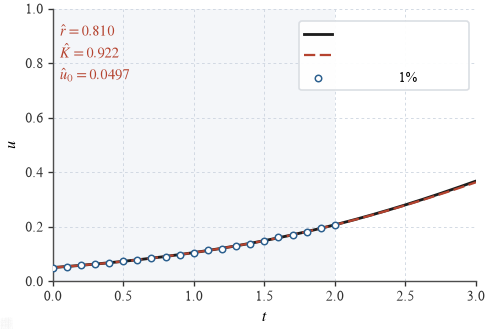

In [7]:
# ---------------------------------------------------------------- 图 28：观测数据与反演曲线
tt = np.linspace(0, 3, 500)
fig, ax = plt.subplots(figsize=(4.55, 2.95))
ax.axvspan(0, 2, color=NAVY, alpha=0.05, lw=0, zorder=0)
ax.plot(tt, logistic(tt), color=INK, lw=1.7, zorder=4, label="真曲线")
ax.plot(tt, logistic(tt, R_HAT, K_HAT, U0_HAT), color=BRICK, lw=1.35, ls=(0, (5, 2)),
        zorder=5, label="反演曲线")
ax.scatter(t_obs, u_obs, s=15, facecolors="white", edgecolors=NAVY, linewidths=0.9,
           zorder=6, label="观测点（1% 噪声）")
ax.text(0.05, 0.90, f"$\\hat r={R_HAT:.3f}$", fontsize=8.8, color=BRICK)
ax.text(0.05, 0.82, f"$\\hat K={K_HAT:.3f}$", fontsize=8.8, color=BRICK)
ax.text(0.05, 0.74, f"$\\hat u_0={U0_HAT:.4f}$", fontsize=8.8, color=BRICK)
ax.text(1.0, 0.40, "采样区间", ha="center", fontsize=7.4, color=NAVY)
ax.set_xlim(0, 3)
ax.set_ylim(0, 1.0)
ax.set_xlabel("$t$")
ax.set_ylabel("$u$")
tidy(ax)
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.98))
save(fig, "A1-G3-3.4-图28.png")
plt.show()

已保存 图片\A1-G3-3.4-图25.png
换初值后，学到的向量场与真解的最大偏差：
  u0=0.02   max|Δu| = 0.0020
  u0=0.05   max|Δu| = 0.0032
  u0=0.2    max|Δu| = 0.0338


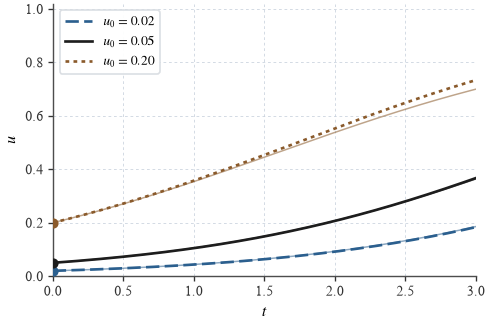

In [8]:
# ---------------------------------------------------------------- 图 25：换初值验证
t = np.linspace(0, 3, 400)
fig, ax = plt.subplots(figsize=(4.55, 2.95))
for u0, col, ls in [(0.02, NAVY, (0, (5, 2))), (0.05, INK, "-"), (0.20, "#8a5a2b", (0, (1.4, 1.6)))]:
    ax.plot(t, logistic(t, u0=u0), color=col, lw=1.6, ls=ls, zorder=4, label=f"$u_0={u0:.2f}$")
    ax.plot(t, logistic(t, R_HAT, K_HAT, u0), color=col, lw=0.9, alpha=0.55, zorder=3)
    ax.scatter([0], [u0], s=26, color=col, zorder=5)
ax.set_xlim(0, 3)
ax.set_ylim(0, 1.02)
ax.set_xlabel("$t$")
ax.set_ylabel("$u$")
tidy(ax)
ax.legend(loc="upper left")
save(fig, "A1-G3-3.4-图25.png")
plt.show()

# 三条初值上的最大偏差（粗线=真解，细线=学到的向量场）
print("换初值后，学到的向量场与真解的最大偏差：")
for u0 in (0.02, 0.05, 0.20):
    err = np.max(np.abs(logistic(t, R_HAT, K_HAT, u0) - logistic(t, u0=u0)))
    print(f"  u0={u0:<5}  max|Δu| = {err:.4f}")

### 实验五　三换验证（§3.2、§3.3、表 2）

**(i) 换初值**：上面图 25 已经把 $u_0=0.02,0.05,0.20$ 三条轨迹都积出来了。若模型只记住了训练那一条
曲线，另外两条会立刻崩；三条都跟着真解走，才说明学到的是**场**。

**(ii) 换步长**：固定 $\theta=0.787$（Euler($h=0.5$) 训练值），换积分器与步长重算 $t=2$。
这一步最能暴露"离散误差被吸收进参数"：用训练时那套装置重算，预测恰好回到真值；换装置就漂。

In [9]:
# ---------------------------------------------------------------- 表 2：换步长之后漂了多少
TH = 0.787
TRUE2 = np.exp(-2)
print(f"表 2　固定 θ={TH}，换一套装置重算 t=2 的值（真值 {TRUE2:.4f}）\n")

rows = [
    ("解析解 e^(-θt)", "—", np.exp(-2 * TH)),
    ("前向 Euler", "0.5（训练时）", (1 - 0.5 * TH) ** 4),
    ("前向 Euler", "0.25", (1 - 0.25 * TH) ** 8),
    ("前向 Euler", "0.125", (1 - 0.125 * TH) ** 16),
    ("经典 RK4", "0.5", rk4_factor(0.5 * TH) ** 4),
    ("经典 RK4", "0.25", rk4_factor(0.25 * TH) ** 8),
]
for name, h, u in rows:
    dev = (u / TRUE2 - 1) * 100
    dev_txt = "%+.1f%%" % (0.0 if abs(dev) < 0.05 else dev)
    print(f"{name:<12}{h:<10}预测={u:.4f}  偏差={dev_txt}")

print("\n结论：训练时那套装置（Euler, h=0.5）恰好回到真值；一旦换装置，偏差就显形，")
print("      而 RK4 无论步长都停在解析值 0.2072——它只是把拟合出的模型算准，救不了参数里的污染。")

表 2　固定 θ=0.787，换一套装置重算 t=2 的值（真值 0.1353）

解析解 e^(-θt) —         预测=0.2072  偏差=+53.1%
前向 Euler    0.5（训练时）  预测=0.1353  偏差=+0.0%
前向 Euler    0.25      预测=0.1733  偏差=+28.1%
前向 Euler    0.125     预测=0.1907  偏差=+40.9%
经典 RK4      0.5       预测=0.2073  偏差=+53.2%
经典 RK4      0.25      预测=0.2072  偏差=+53.1%

结论：训练时那套装置（Euler, h=0.5）恰好回到真值；一旦换装置，偏差就显形，
      而 RK4 无论步长都停在解析值 0.2072——它只是把拟合出的模型算准，救不了参数里的污染。


### 实验六　两笔“AI 的账”：表示能力与梯度成本（图 6 右、图 11）

正文 §1.1 与 §1.3 各有一笔账，都不需要训练网络，只要会数数。

**账一：为什么要用网络。** 同样做到精度 $\varepsilon$，三次张量积多项式需要
$O(\varepsilon^{-d/3})$ 个基函数（指数上挂着维数 $d$），而宽度 $w$、深度 $L$ 的网络只有
$O(Lw^2)$ 个参数，与 $d$ 无关。取 $\varepsilon=10^{-2}$、$w=64$、$L=3$，把两边列出来。

**账二：梯度有多贵。** 参数 $P$ 个时，有限差分算一次全梯度要 $2P$ 次前向，反向模式只要约
2 次——这就是“梯度不随参数个数变贵”。

In [10]:
# ---------------------------------------------------------------- 图 6 右：表示能力的账
import numpy as np

EPS = 1e-2          # 目标精度
W, L = 64, 3        # 网络宽度、深度


def poly_basis(d, eps=EPS):
    '''三次张量积多项式：做到精度 eps 需要的基函数个数（量级）。'''
    return eps ** (-d / 3.0)


def mlp_params(d, w=W, l=L):
    '''输入 d 维、宽度 w、深度 l 的全连接网络参数个数。'''
    return (d + 1) * w + (l - 1) * w * w + w


print("维数 d   多项式基函数      网络参数      倍数")
for d in (2, 5, 10, 20, 50):
    a, b = poly_basis(d), mlp_params(d)
    print(f"{d:5d}   {a:12.2e}   {b:10.0f}   {a / b:9.1e}")

print("\n结论：d=20 时多项式要 ~10^13 个基函数，而网络一侧只要 ~10^4 个参数。")
print("但这条账只对“光滑度受限、维数很高”的函数类成立；一维解析函数上，谱方法远比网络划算。")

维数 d   多项式基函数      网络参数      倍数
    2       2.15e+01         8448     2.6e-03
    5       2.15e+03         8640     2.5e-01
   10       4.64e+06         8960     5.2e+02
   20       2.15e+13         9600     2.2e+09
   50       2.15e+33        11520     1.9e+29

结论：d=20 时多项式要 ~10^13 个基函数，而网络一侧只要 ~10^4 个参数。
但这条账只对“光滑度受限、维数很高”的函数类成立；一维解析函数上，谱方法远比网络划算。


In [11]:
# ---------------------------------------------------------------- 图 11：算一次全梯度要多少次前向
print("参数个数 P   有限差分 2P      反向模式 / 伴随法")
for P in (1e2, 1e4, 1e6, 1e9):
    print(f"{P:10.0e}   {2 * P:12.0e}   {2:12d}")

print("\nP = 10^6 时，两者差 6 个数量级：这不是“快一点”，而是“能不能做”。")

参数个数 P   有限差分 2P      反向模式 / 伴随法
     1e+02          2e+02              2
     1e+04          2e+04              2
     1e+06          2e+06              2
     1e+09          2e+09              2

P = 10^6 时，两者差 6 个数量级：这不是“快一点”，而是“能不能做”。


### 实验七　权重与学习率：两件“训练侧”的账（图 19、图 26）

§2.3 说“权重给歪了，网络就偏科”，§3.4 说“学习率就是步长”。这两件事都可以在一个
两参数的玩具模型上算出来。

**（a）偏科。** 取 $L_r(\theta)=\frac12\kappa\theta_1^2$、$L_b(\theta)=\frac12(\theta_2-1)^2$，
$\kappa=50$，学习率 $\eta=4\times10^{-4}$（被 $\kappa$ 卡住，再大就发散）：

- 权重 $1:1$ 时，残差项几步就到底（收敛率 $\eta\kappa=0.02$），边界项只以 $\eta=4\times10^{-4}$
  的速度爬——600 步后残差降到 $10^{-10}$，边界还在 $O(1)$；
- 权重按曲率比取 $50:1$，两项才以同一个速率下降。

**（b）学习率。** 在 $\mu=1$ 的二次函数上做梯度下降，收敛条件是 $|1-\eta\mu|<1$，
即 $\eta<2/\mu$。下面把四条学习率的轨迹都算出来。

In [12]:
# ---------------------------------------------------------------- 图 19：权重偏科
KAPPA, ETA, STEPS = 50.0, 4e-4, 600


def run(lam, kappa=KAPPA, eta=ETA, steps=STEPS, th0=(0.5, -1.0)):
    '''两项损失的玩具模型：残差项曲率 kappa，边界项曲率 1。'''
    th = np.array(th0, float)
    hist = []
    for _ in range(steps):
        g_r = np.array([kappa * th[0], 0.0])
        g_b = np.array([0.0, th[1] - 1.0])
        hist.append((0.5 * kappa * th[0] ** 2, 0.5 * (th[1] - 1.0) ** 2))
        th = th - eta * (g_r + lam * g_b)
    return np.array(hist)


for lam, tag in [(1.0, "权重 1:1（照抄）"), (KAPPA, "权重 50:1（按曲率比）")]:
    h = run(lam)
    print(f"{tag:<22} 第 1 步: L_r={h[0, 0]:8.2e}  L_b={h[0, 1]:8.2e}")
    print(f"{'':<22} 第 600 步: L_r={h[-1, 0]:8.2e}  L_b={h[-1, 1]:8.2e}")

print("\n同一个学习率下，两项的收敛率分别是 eta*kappa = %.4f 与 eta*1 = %.4f，差 50 倍。" % (ETA * KAPPA, ETA))

权重 1:1（照抄）             第 1 步: L_r=6.25e+00  L_b=2.00e+00
                       第 600 步: L_r=1.93e-10  L_b=1.24e+00
权重 50:1（按曲率比）          第 1 步: L_r=6.25e+00  L_b=2.00e+00
                       第 600 步: L_r=1.93e-10  L_b=6.16e-11

同一个学习率下，两项的收敛率分别是 eta*kappa = 0.0200 与 eta*1 = 0.0004，差 50 倍。


In [13]:
# ---------------------------------------------------------------- 图 26：学习率就是步长
MU = 1.0
print("eta        |1-eta*mu|   第10步损失    第40步损失   收敛？")
for eta in (0.2, 1.0, 1.9, 2.2):
    L = 0.5 * (1 - eta * MU) ** (2 * np.arange(1, 41))
    ok = abs(1 - eta * MU) < 1
    print(f"{eta:4.1f}   {abs(1 - eta * MU):10.2f}   {L[9]:11.3e}   {L[39]:11.3e}   {'是' if ok else '否（发散）'}")

print(f"\n稳定域要求 eta < 2/mu = {2 / MU:.2f}；eta=1.0 时 1-eta*mu=0，一步到底。")
print("这与 Euler 的稳定域 |1+h*mu|<1 是同一个不等式：学习率就是步长。")

eta        |1-eta*mu|   第10步损失    第40步损失   收敛？
 0.2         0.80     5.765e-03     8.834e-09   是
 1.0         0.00     0.000e+00     0.000e+00   是
 1.9         0.90     6.079e-02     1.092e-04   是
 2.2         1.20     1.917e+01     1.080e+06   否（发散）

稳定域要求 eta < 2/mu = 2.00；eta=1.0 时 1-eta*mu=0，一步到底。
这与 Euler 的稳定域 |1+h*mu|<1 是同一个不等式：学习率就是步长。


### 结论与复现说明

1. **训练误差为 0 什么也证明不了。** 实验一里四种组合的训练点误差都是 0，外推却差 53%。
2. **离散误差会被参数吸走。** 实验二显示 $1-\theta$ 随 $h$ 线性减小；实验五显示用训练时那套
   装置重算时误差恰好抵消，换装置立刻暴露。
3. **残差 ≠ 误差。** 实验三里，一个配点就能把残差损失压到 0，而真实误差仍有 0.72。
4. **验证必须“换”。** 实验四把 $\theta=(r,K,u_0)$ 反演出来：$r$ 准（数据里看得出增长），
   $K$ 偏小（窗口内曲线还没弯），所以换初值/换区间才能说明模型学到的是场。
5. **AI 的三笔账也能量出来。** 实验六：同一精度下多项式基函数随维数指数增长，而网络参数
   只线性增长；梯度成本上，有限差分随参数个数线性增长，反向模式是常数。实验七：权重按曲率
   配平前后，两项损失的下降速率差 50 倍；学习率一旦越过 $2/\mu$，损失立刻发散。

**复现**：`Run All`（约几秒）。图 14、15、18、25、28 由本 Notebook 重新生成，写入 `图片/`，
与正文插图同名，可直接覆盖；图 6、11、19、26 是正文插图脚本画的示意图，本 Notebook 只把
它们背后的数字算出来（实验六、七）。所有数字与正文表 1、表 2 一致（正文的四舍五入以这里为准）。